# Figures for Paper

In [1]:

import os 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.io import loadmat


from pynav import QAgent, TwoQAgent

actions = {
    0 : np.asarray([ 1, 0], dtype=np.int32), 
    1 : np.asarray([-1, 0], dtype=np.int32), 
    2 : np.asarray([0,  1], dtype=np.int32), 
    3 : np.asarray([0, -1], dtype=np.int32) 
}

settings = ['dense', 'middle', 'sparse', 'sparser']

box_colors = [
    '#4D7F8D',
    '#D6833B',
    '#3E6F1D',
    '#515151'
]


median_colors = [
    '#00eff1',
    '#995555',
    'lightgreen',
    '#ffffff'
]





action_labels = ['up', 'down', 'right', 'left']
data_labels = ['Dense', 'Middle', 'Sparse', 'Sparser']

os.makedirs("./plots/single_Q", exist_ok=True)
os.makedirs("./plots/beta_Q", exist_ok=True)
os.makedirs("./plots/two_Q", exist_ok=True)
os.makedirs("./plots/general", exist_ok=True)

for path_name in  ['single_Q', 'two_Q', 'two_single_Q']:
  for type_name in ['trajectories', 'characterization', 'performance']:
    os.makedirs(f"./plots/{path_name}/{type_name}", exist_ok=True)
os.makedirs("./plots/two_Q/single_vs_two", exist_ok=True)



## Data

In [2]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path
noise_thresholds = [1e-6, 3e-6, 5e-6, 7e-6]
data_environments= {}
start_regions = {}


for (i, n_thr) in enumerate(noise_thresholds):
    new_data = data.copy()
    new_data[new_data < n_thr] = 1e-20
    data_environments[n_thr] = new_data
    start_region = np.any(data >= n_thr, axis=0) 
    start_regions[n_thr] = (start_region / np.sum(start_region))#.ravel()


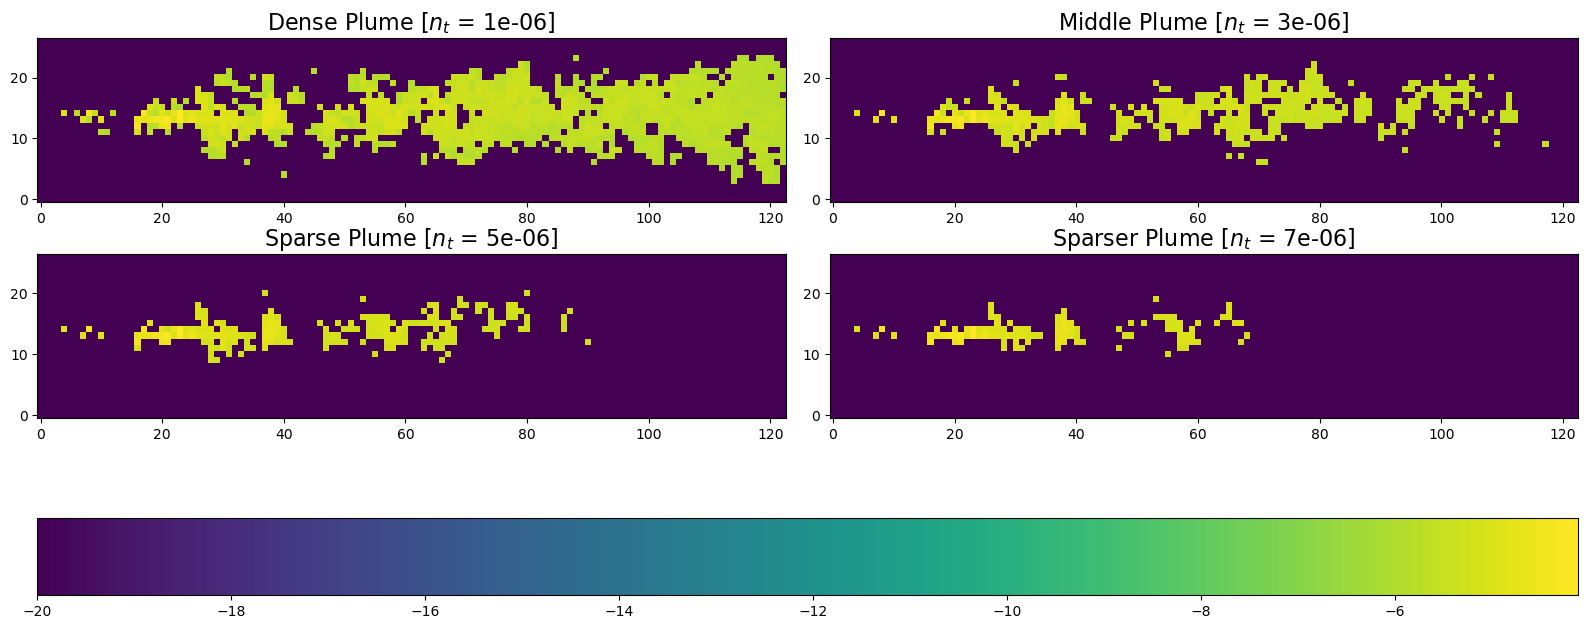

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))

axes = axes.flatten()
for (i, (n_thr, data)) in enumerate(data_environments.items()):
    axes[i].set_title("{} Plume [$n_t$ = {}]".format(data_labels[i], n_thr), fontsize=16)
    log_data = np.log10(data[100, :, :])
    im = axes[i].imshow(log_data, cmap='viridis', origin='lower', vmax=log_data.max(), rasterized=True)
    
fig.tight_layout()
fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')
fig.savefig("./plots/general/signals.pdf", bbox_inches='tight')


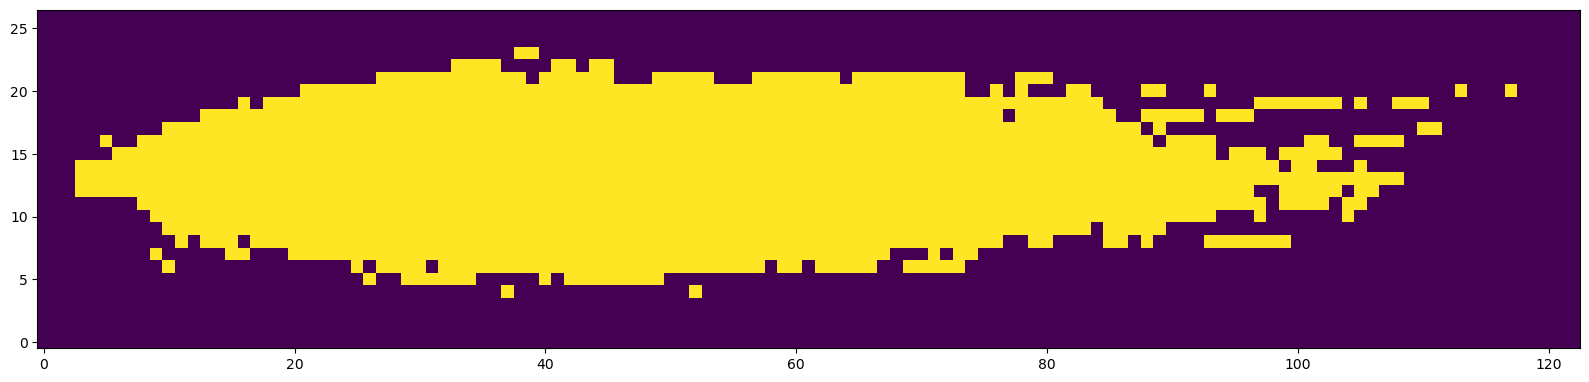

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(16, 5))
start_region = start_regions[7e-6].copy()
start_region[:, :3] = 0.0
ax.imshow(start_region, cmap='viridis', origin='lower',rasterized=True)    
fig.tight_layout()
fig.savefig("./plots/general/start_region.pdf", bbox_inches='tight')

## Figure 2

In [5]:
out_path = "./plots/single_Q"
agent = QAgent(500)

### Figure 2 (a): Structure of a trajectory and examples of dense, middle and sparse trajectories


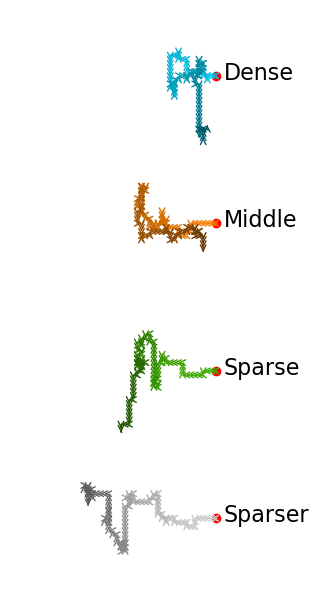

In [6]:


Qs = [
    ('Dense', "/storage/rando/pynav_results_new/single_Q/dense/agent_6299/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/single_Q/middle/agent_1574/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/single_Q/sparse/agent_944/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', "/storage/rando/pynav_results_new/single_Q/sparser/agent_944/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(1, 500):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str, rasterized=True )
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ), rasterized=True)

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()
fig.savefig(f"{out_path}/trajectories/sample_trajectories.pdf", bbox_inches='tight')

### Figure 2 (supplemental): All policies

In [35]:
Qs = [
    ('Dense',  "/storage/rando/pynav_results_new/single_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/single_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/single_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',"/storage/rando/pynav_results_new/single_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]


for (label, main_path, color_rgb) in Qs:
    dirs= os.listdir(main_path)
    n_plots = len(dirs) // 5 # + 1
    fig, ax = plt.subplots(n_plots, 5, figsize=(14, 3*n_plots))


    axes = ax.flatten()
    for i in range(len(dirs)):
        agent.load_q(f"{main_path}/{dirs[i]}/Q_stored/Qfun.npy")
        
        pos = np.array([0, 0])
        ax = axes[i]
        path = [pos.copy()]
        plot_steps = 100
        for j in range(1, plot_steps + 1):
            pos += actions[np.argmax(agent.Q[j])]
            path.append(pos.copy())

        for j in range(plot_steps): 
            ax.plot(path[j][1], path[j][0], '.', ms=0.5, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
            ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='-', color=((170 - (j+1))/170) * color_rgb), rasterized=True)
        ax.plot(path[0][1], path[0][0], 'o', ms=1.0, c='red', label='starting point')

        ax.set_xlim([-50, 5.0])
#        ax.set_ylim([-40, 40.0])
        ax.set_axis_off()
        ax.set_aspect('equal')
    
    # if len(dirs) < len(axes):
    #     for i in range(len(axes) - len(dirs)):
    #         axes[-i-1].set_axis_off()
    fig.subplots_adjust(hspace=0)
    fig.savefig(f"{out_path}//trajectories/single_q_policies_trained_on_{label}.pdf", bbox_inches='tight')
    plt.close(fig)
    print(f"[--] Completed {label}")


[--] Completed Dense
[--] Completed Middle
[--] Completed Sparse
[--] Completed Sparser


In [36]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
base_dir = "/storage/rando/pynav_results_new/single_Q"

tr_max_void = [[], [], [], []]
tr_mean_void = [[], [], [], []]

tr_max_steps = [[], [], [], []]
tr_mean_steps = [[], [], [], []]


tr_max_state =  [[], [], [], []]
tr_mean_state =  [[], [], [], []]

delta = 500

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/training.log", 'r') as f:
            num_void_steps, num_steps = [], []
            for line in f.readlines()[-delta:]:
                num_void_steps.append(int(line.split(',')[-1]))
                num_steps.append(int(line.split(',')[-2]))
            
            tr_max_void[i].append(np.max(num_void_steps))
            tr_mean_void[i].append(np.mean(num_void_steps))
            tr_max_steps[i].append(np.max(num_steps))
            tr_mean_steps[i].append(np.mean(num_steps))


        tr_states = np.load(f"{base_dir}/{setting}/agent_{seed}/training_max_void_lengths.npy")
        tr_max_state[i].append(np.max(tr_states[-delta:]))
        tr_mean_state[i].append(np.mean(tr_states[-delta:]))

    print(f"[--] Completed setting {setting}")



[--] Completed setting dense
[--] Completed setting middle
[--] Completed setting sparse
[--] Completed setting sparser


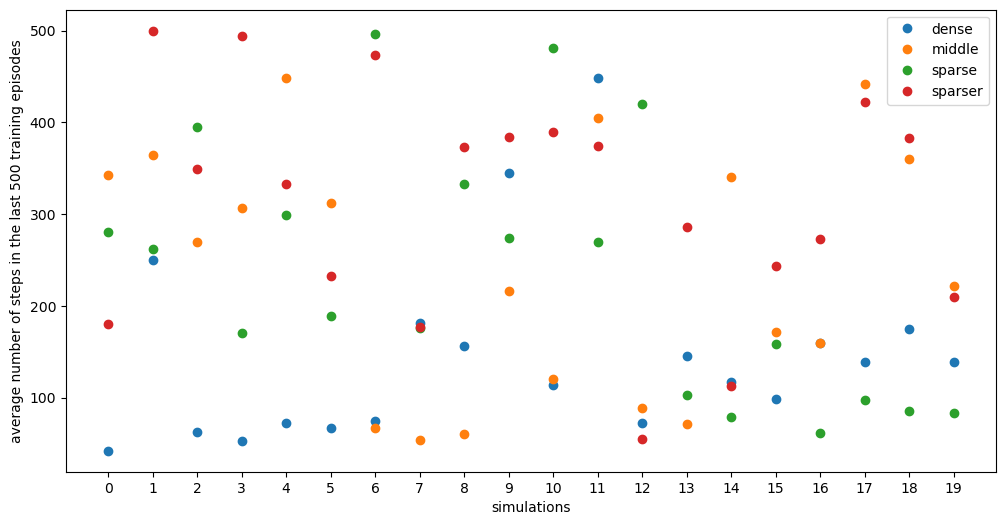

In [37]:
fig, ax = plt.subplots(figsize=(12, 6))
for i in range(len(settings)):
    mu = np.array(tr_max_state[i])
    ax.plot(range(mu.shape[0]), mu, 'o', lw=3, label=settings[i], rasterized=True)
    
ax.set_xticks(range(0, 20))
    
ax.set_xlabel("simulations")
ax.set_ylabel(f"average number of steps in the last {delta} training episodes")
    
ax.legend()

In [7]:
def compute_surge_length(Q_file, num_accepted_steps = 2, count_from = 1, count_to = None):
    agent.load_q(Q_file)
#    print(agent.Q.shape)
    num_left = 0
    num_updown = 0
    count_to = agent.Q.shape[0] if count_to is None else count_to
    for i in range(count_from, count_to):
        if np.argmax(agent.Q[i]) == 3:
            num_left += 1
        if np.argmax(agent.Q[i]) == 0 or np.argmax(agent.Q[i]) ==1:
            num_updown += 1
        else:
            num_updown = 0
        if num_updown >= num_accepted_steps:
            break 
    return max(num_left  - num_accepted_steps, 0)

def compute_backtracking_length(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    max_pos = (0, 0, pos)
    for i in range(count_from, avg_void+1):
        pos += actions[np.argmax(agent.Q[i])]
        if max_pos[1] > pos[1]:
            max_pos = (i, pos[1], pos)
            
    back_pos = max_pos[2]
    pos = max_pos[2]
    for i in range(max_pos[0], avg_void + 1):
        pos += actions[np.argmax(agent.Q[i])]
        if back_pos[1] < pos[1]:
            back_pos = (i, pos[1], pos)
        
    return abs(back_pos[1] - max_pos[1])


def compute_backtracking_init_time(Q_file, avg_void, acceptance_steps = 2, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    num_right = 0
    for i in range(count_from, avg_void+1):
        if np.argmax(agent.Q[i]) == 2:
            num_right += 1
        elif np.argmax(agent.Q[i]) == 3:
            num_right = 0 
        if num_right > acceptance_steps:
            break
    return max(i - acceptance_steps - count_from, 0)


def compute_search_length(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    pos = np.zeros(2)
    max_pos = 0
    for i in range(count_from, avg_void+1):
        pos += actions[np.argmax(agent.Q[i])]
        max_pos = min(pos[1], max_pos)
    return abs(max_pos)

def compute_cast_width(Q_file, avg_void, count_from=1):
    agent.load_q(Q_file)
    max_pos = 0.0
    min_pos = 0.0
    pos = np.zeros(2)
    for i in range(count_from, avg_void +1):
        pos += actions[np.argmax(agent.Q[i])]
        max_pos = max(pos[0], max_pos, 0)
        min_pos = min(pos[0], min_pos, 0)
    return max_pos + abs(min_pos)




In [83]:

metric_names = ["mean_state", "max_state", "mean_void", "max_void", "entire_traj"]
metrics = [tr_mean_state, tr_max_state, tr_mean_void, tr_max_void, 500]


NameError: name 'tr_mean_state' is not defined

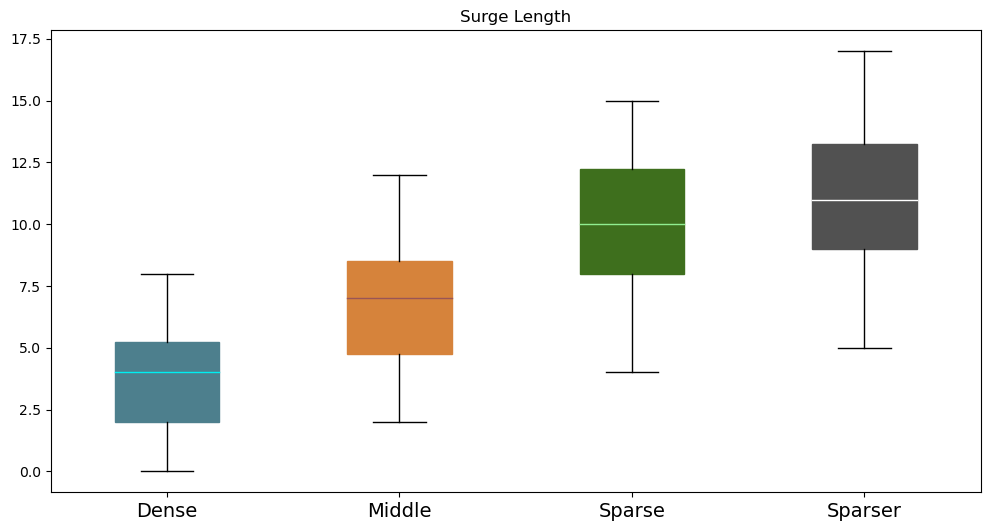

In [39]:


surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", num_accepted_steps=3))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


ax.set_title("Surge Length")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/surge_length.pdf", bbox_inches='tight')



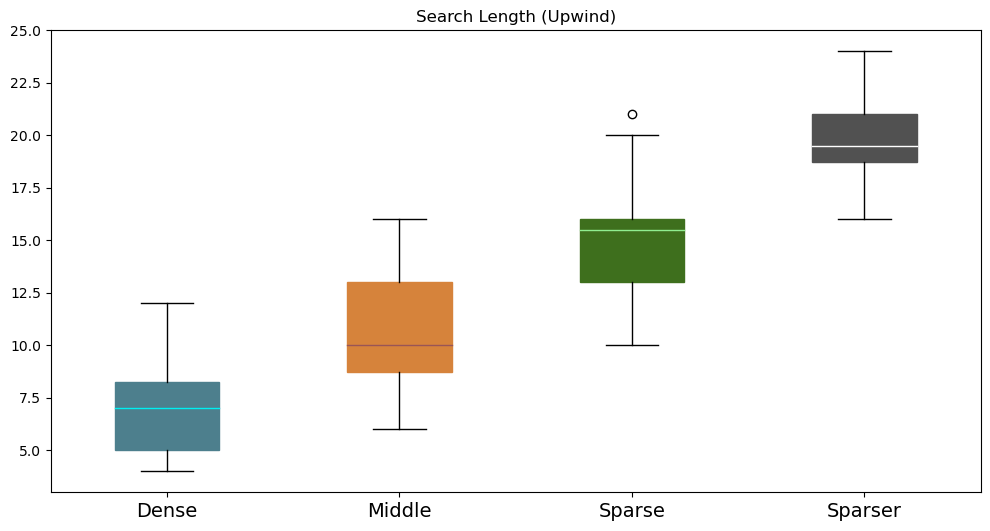

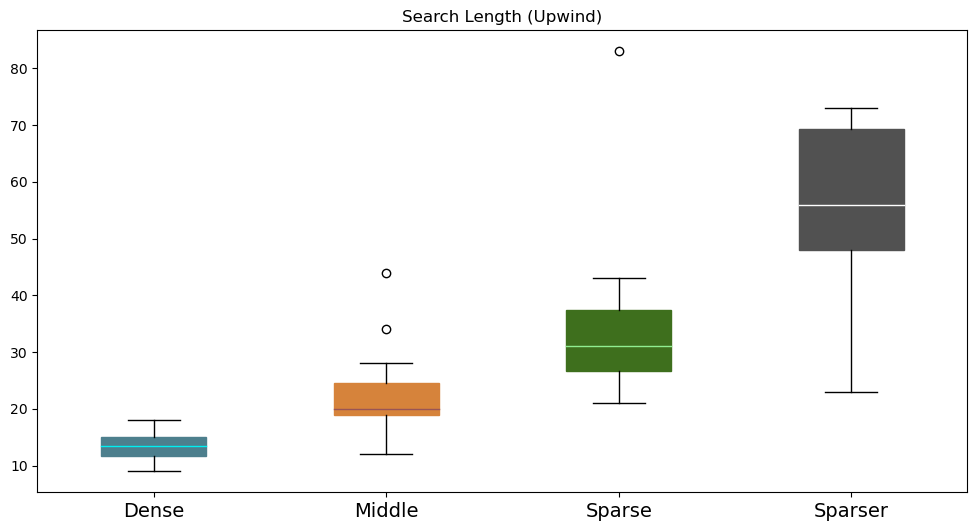

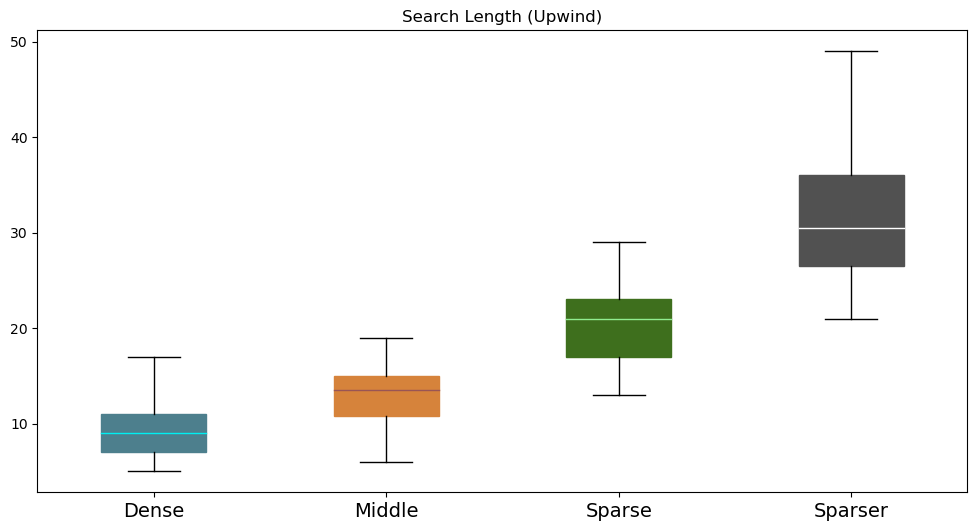

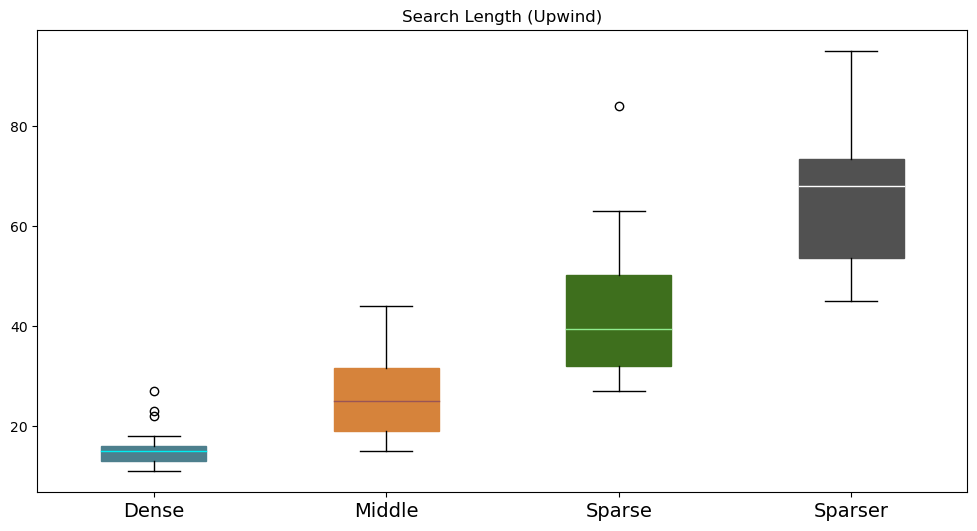

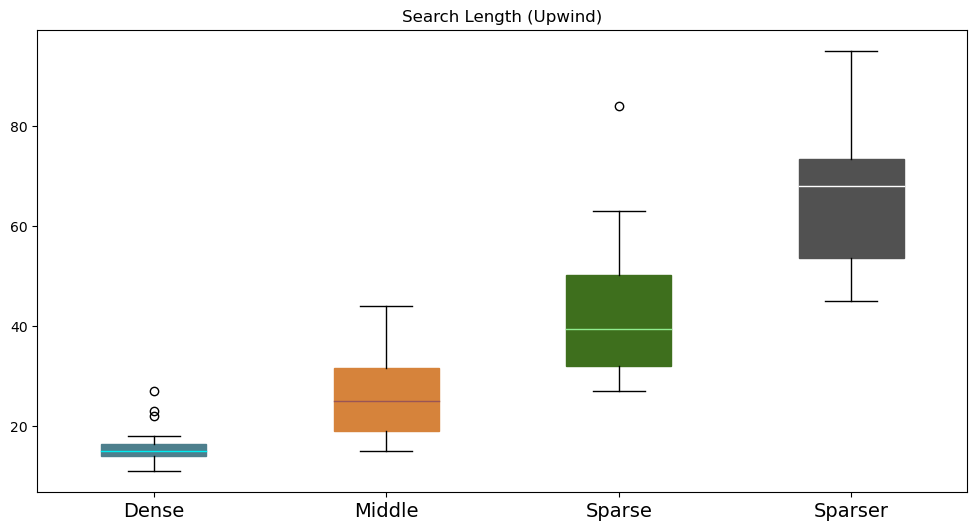

In [40]:

for met,met_name in zip(metrics, metric_names):

	search_len = [[], [], [], []]
	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
					else:
						search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(search_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title("Search Length (Upwind)")
	ax.set_xticklabels(data_labels, fontsize=14)

	fig.savefig(f"{out_path}/characterization/search_length_{met_name}.pdf", bbox_inches='tight')




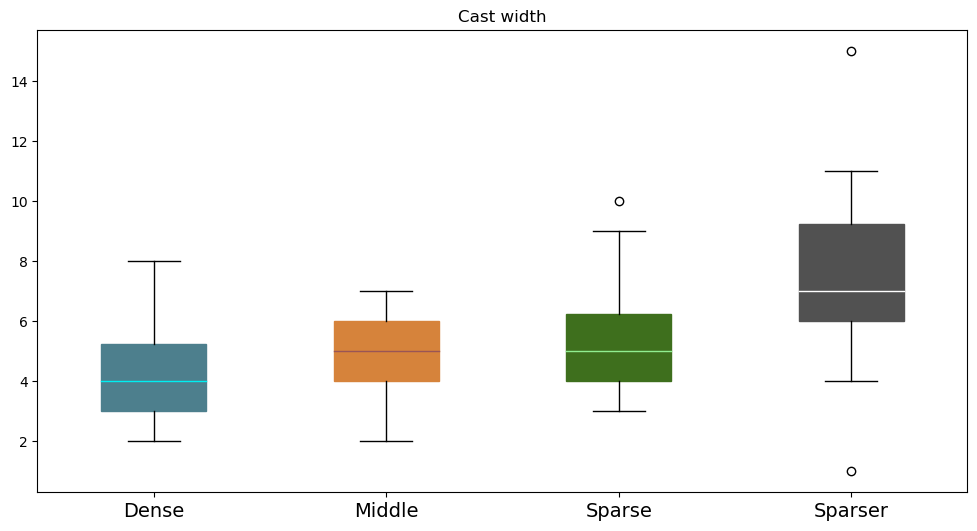

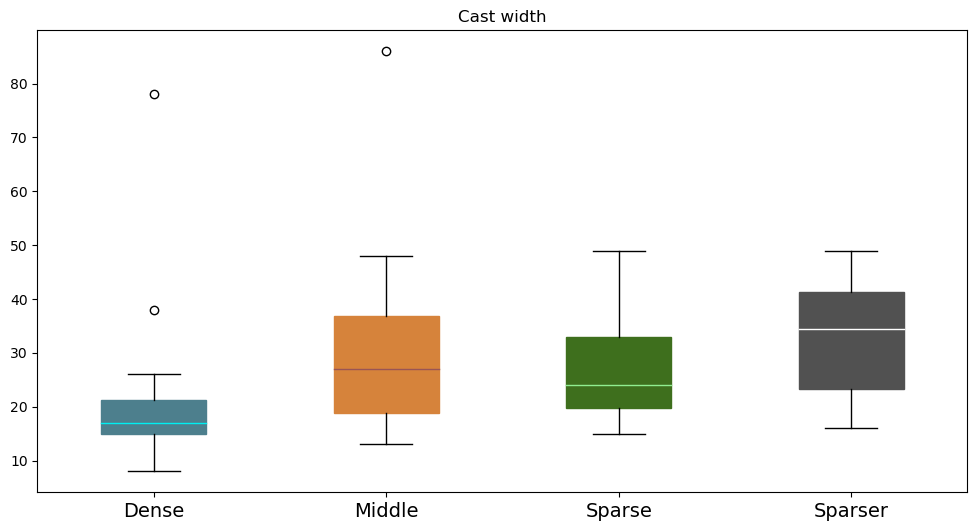

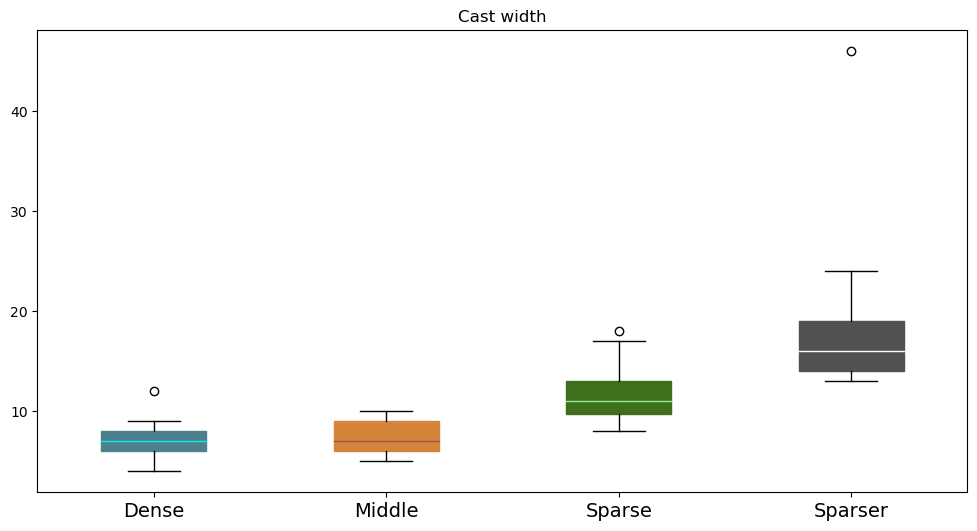

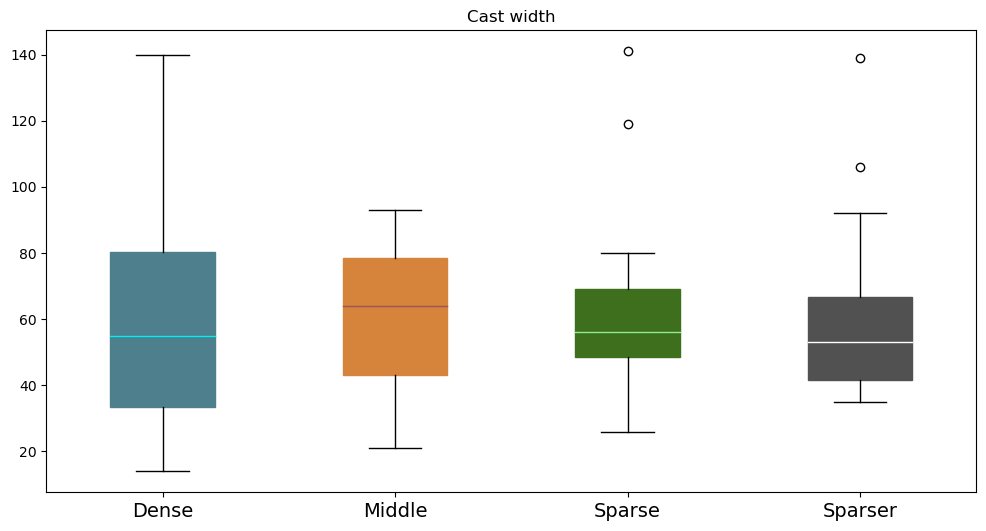

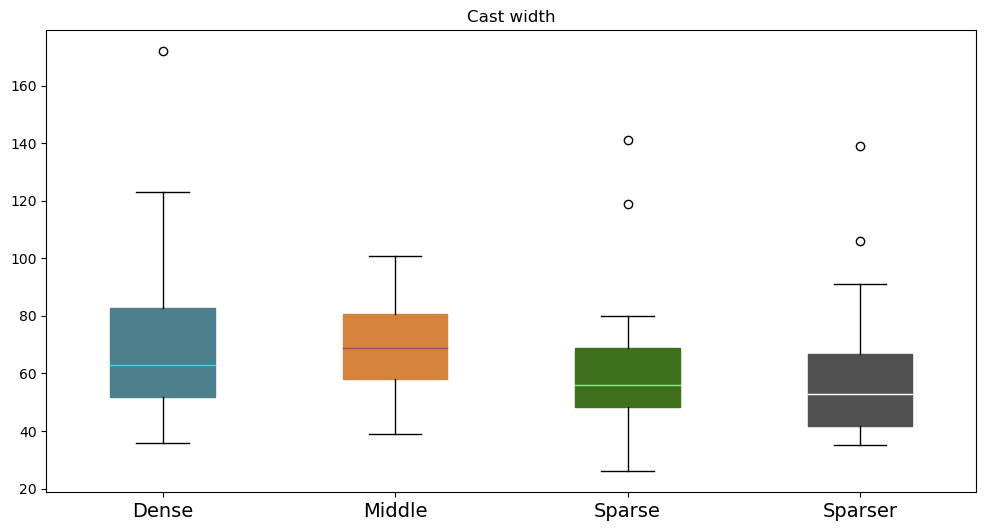

In [41]:



for met,met_name in zip(metrics, metric_names):
	cast_width = [[], [], [], []]

	for (i, setting) in enumerate(settings):
		for (j, seed) in enumerate(agent_seeds):
						if met_name == 'entire_traj':
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
						else:
							cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 



	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(cast_width, patch_artist=True)

	for i in range(len(b['boxes'])):
		b['boxes'][i].set_color(box_colors[i])
		b['medians'][i].set_color(median_colors[i])


	ax.set_title("Cast width")
	ax.set_xticklabels(data_labels, fontsize=14)
	fig.savefig(f"{out_path}/characterization/cast_width_{met_name}.pdf", bbox_inches='tight')
			




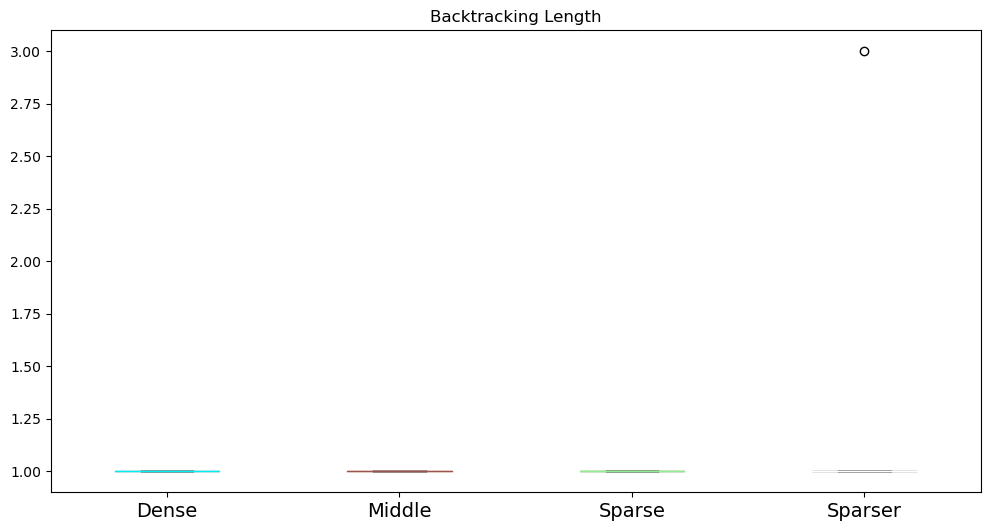

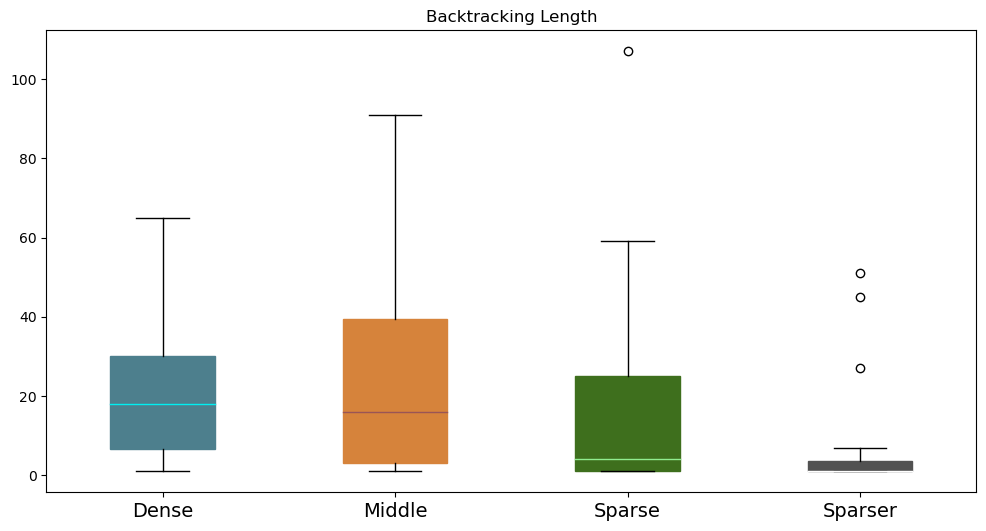

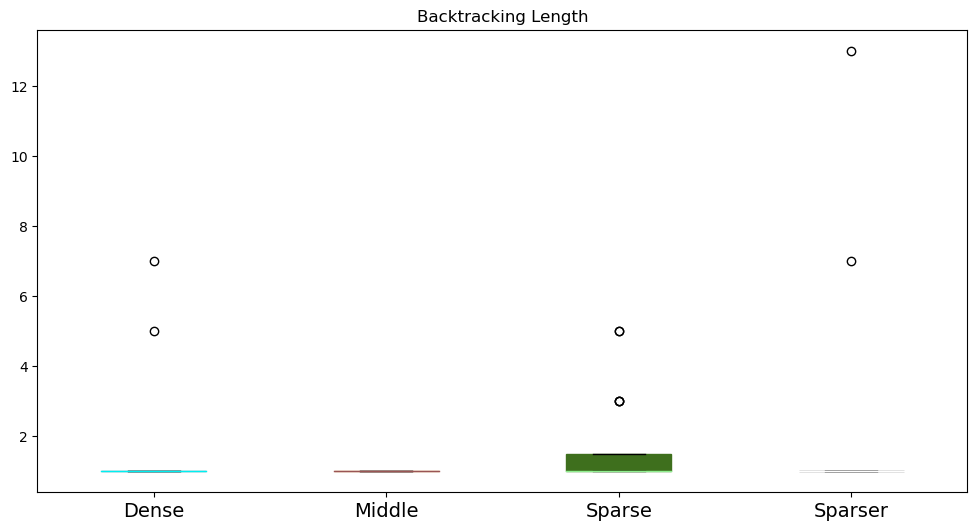

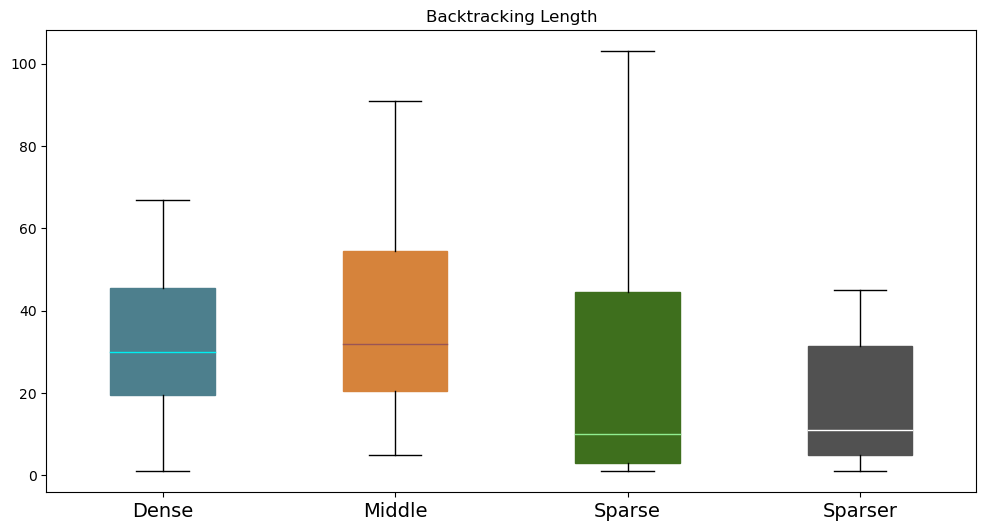

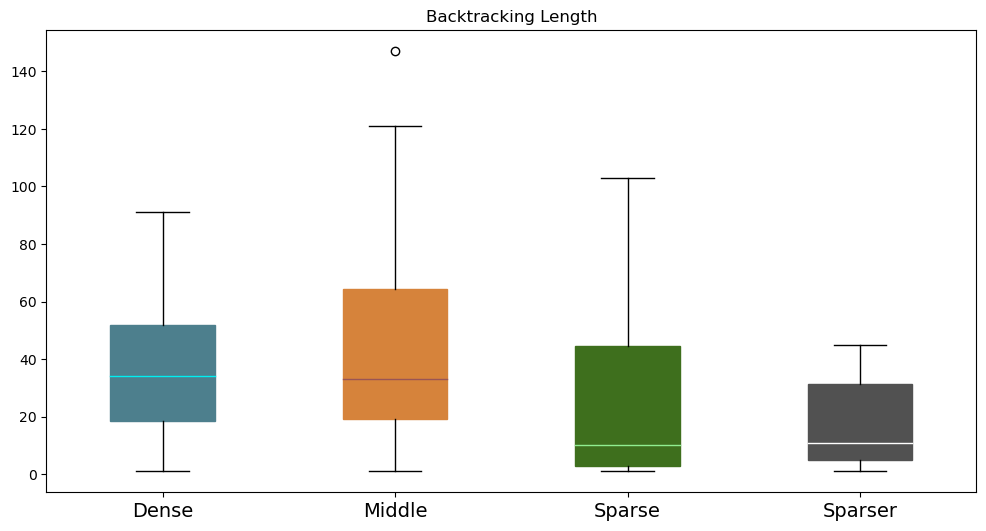

In [42]:

for met,met_name in zip(metrics, metric_names):

	bck_len = [[], [], [], []]

	for (i, setting) in enumerate(settings):
			for (j, seed) in enumerate(agent_seeds):
					if met_name == 'entire_traj':
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500 ) ) 
					else:
						bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met[i][j]) ) ) 


	fig, ax = plt.subplots(1, 1, figsize=(12, 6))

	b = ax.boxplot(bck_len, patch_artist=True)
	for i in range(len(b['boxes'])):
			b['boxes'][i].set_color(box_colors[i])
			b['medians'][i].set_color(median_colors[i])

	ax.set_title("Backtracking Length")
	ax.set_xticklabels(data_labels, fontsize=14)
	fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}.pdf", bbox_inches='tight')
#	plt.close(fig)



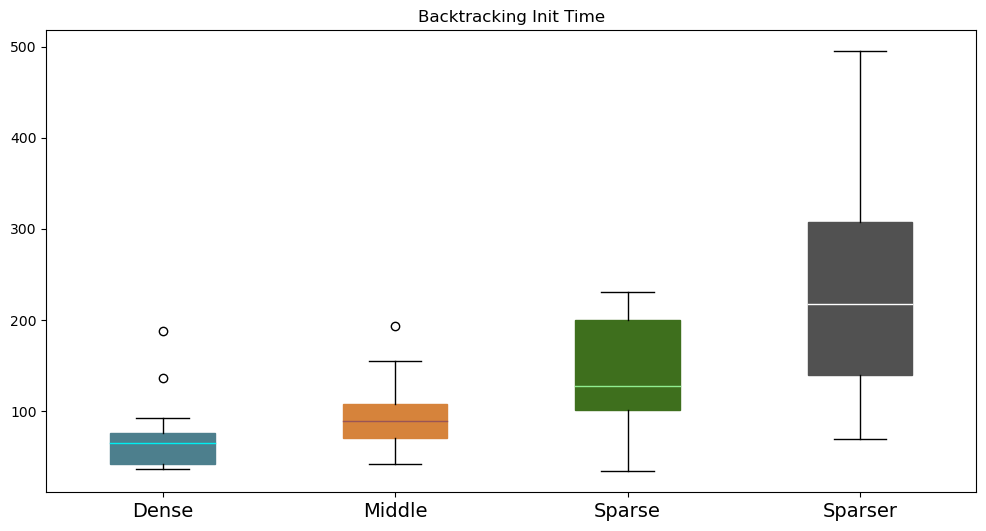

In [43]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/Q_stored/Qfun.npy", 500, acc_steps ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/backtracking_init_time.pdf", bbox_inches='tight')
#plt.close(fig)


In [44]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"

Q_nums = [0, 50000, 100000, 500000, 1000000, 1500000, 2000000, 2500000, 3000000]

last_detections = {setting : [[] for _ in range(len(Q_nums))] for setting in settings}


for setting in settings:
    for seed in agent_seeds:
        for i in range(len(Q_nums)):       
            with open(f"{base_dir}/{setting}/agent_{seed}/test/{setting}/Q_{Q_nums[i]}/failed_last_detections.log", 'r') as f:
                last_detections[setting][i] += [float(x.split(',')[1]) for x in f.readlines()]


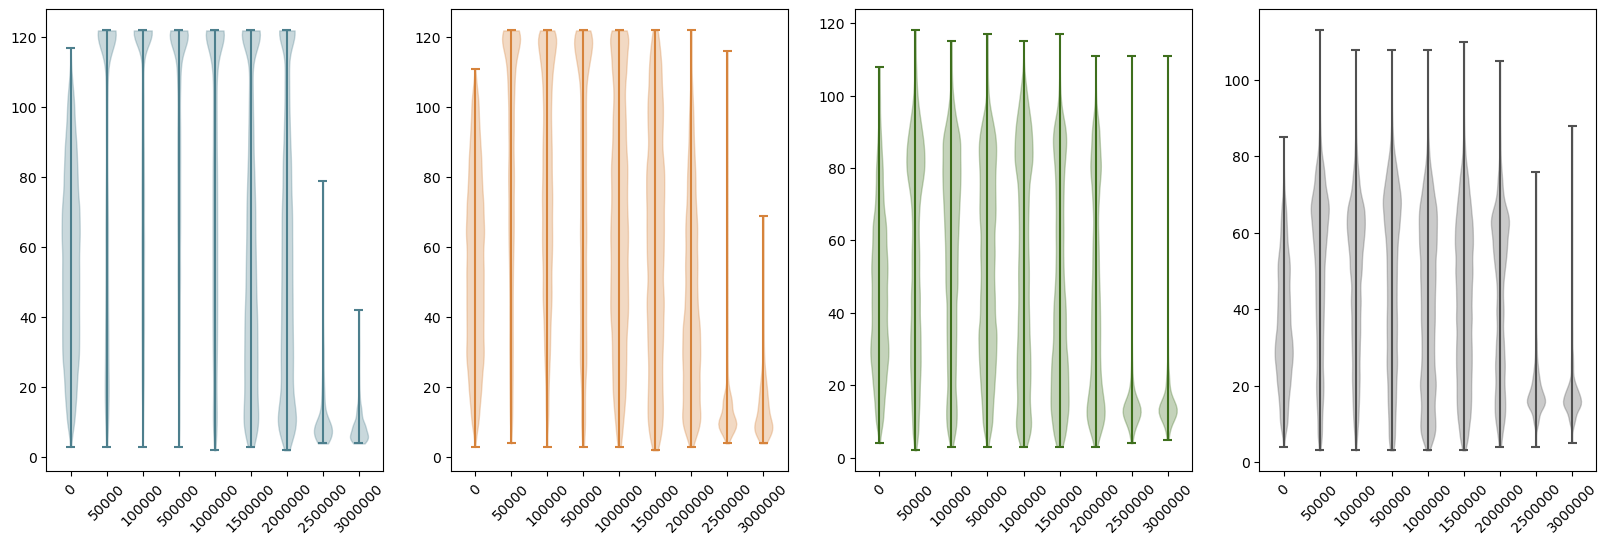

In [45]:



fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for (idx, label) in zip(range(4), data_labels):

    violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=range(len(Q_nums)))


    for e in violin['bodies']:
        e.set_facecolor(box_colors[idx])
        e.set_edgecolor(box_colors[idx])

    for lab in ['cbars', 'cmins', 'cmaxes']:
        violin[lab].set_edgecolor(box_colors[idx])
        violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_ylim([0, 30])
    axes[idx].set_xticks(range(len(Q_nums)), Q_nums, rotation=45)
fig.savefig(f"{out_path}/performance/failed_positions_during_training.pdf", bbox_inches='tight')



In [39]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path

blanks = {}
num_blanks = {}
mean_blank_map = {}

for n_thr in noise_thresholds:
    new_data = data.copy()
    new_data[new_data < n_thr] = 0.0
    blanks[n_thr] = []
    mean_blank_map[n_thr] = np.zeros((data.shape[1], data.shape[2]))
    num_blanks[n_thr] = 0
    for i in range(new_data.shape[1]):
        for j in range(new_data.shape[2]):
            obs = new_data[:, i, j] > n_thr
            count_zero = 0 
            avg_blank = []
            init_idx = np.argmax(obs)
            for k in range(init_idx + 1, len(obs)):
                if not obs[k]:
                    count_zero +=1
                else:
                    if count_zero > 0:
                        avg_blank.append(count_zero)
                    count_zero = 0
            if len(avg_blank) >0:
              blanks[n_thr] += avg_blank
              num_blanks[n_thr] += len(avg_blank)
              mean_blank_map[n_thr][i, j] = np.mean(avg_blank)


In [40]:
for n_thr in noise_thresholds:
  print("[++] n_thr = {}\n\t[--] Avg blank: {} +/- {}\n\t[--] 10-th Percentile: {}\t95-th Percentile: {}\n\t[--] min: {}\tmax: {}".format(n_thr, np.mean(blanks[n_thr]), np.std(blanks[n_thr]), np.percentile(blanks[n_thr], q=10), np.percentile(blanks[n_thr], q=85), np.min(blanks[n_thr]), np.max(blanks[n_thr]) ))
#  print("[--] Num blank: {}".format(num_blanks[n_thr]))

mean_blanks = np.array([np.mean(blanks[n_thr]) for n_thr in noise_thresholds])
std_blanks  = np.array([np.std(blanks[n_thr]) for n_thr in noise_thresholds])
p10_blanks = np.array([np.percentile(blanks[n_thr], q=10) for n_thr in noise_thresholds])
p95_blanks  = np.array([np.percentile(blanks[n_thr], q=85) for n_thr in noise_thresholds])


[++] n_thr = 1e-06
	[--] Avg blank: 7.76735137000871 +/- 35.81702944664332
	[--] 10-th Percentile: 1.0	95-th Percentile: 9.0
	[--] min: 1	max: 2391
[++] n_thr = 3e-06
	[--] Avg blank: 10.130460379733345 +/- 40.77479696107458
	[--] 10-th Percentile: 1.0	95-th Percentile: 12.0
	[--] min: 1	max: 2294
[++] n_thr = 5e-06
	[--] Avg blank: 14.036780889541744 +/- 57.4398311063933
	[--] 10-th Percentile: 1.0	95-th Percentile: 15.0
	[--] min: 1	max: 2241
[++] n_thr = 7e-06
	[--] Avg blank: 15.618002129542148 +/- 63.44280576620886
	[--] 10-th Percentile: 1.0	95-th Percentile: 17.0
	[--] min: 1	max: 2272


/tmp/ipykernel_338316/1455725806.py:10: RuntimeWarning: divide by zero encountered in log10
  ax.imshow(np.log10(mean_blank_map[noise_thresholds[i]]), origin='lower', cmap='viridis', rasterized=True)


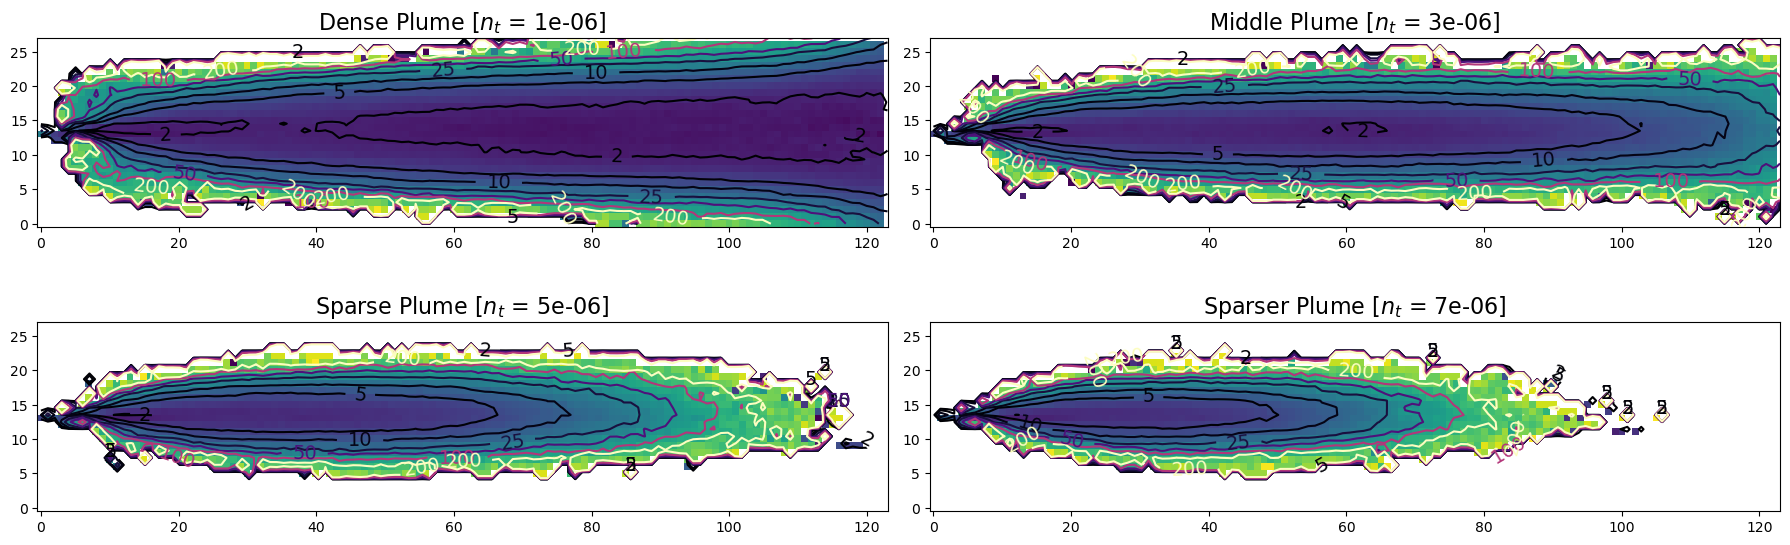

In [42]:
y = np.linspace(0, data.shape[1], data.shape[1])
x = np.linspace(0, data.shape[2], data.shape[2])
X, Y = np.meshgrid(x, y)

fig, axes = plt.subplots(2, 2, figsize=(18, 6))
axes = axes.flatten()
for i in range(len(noise_thresholds)):
  ax = axes[i]
  ax.set_title("{} Plume [$n_t$ = {}]".format(data_labels[i], noise_thresholds[i]), fontsize=16)
  ax.imshow(np.log10(mean_blank_map[noise_thresholds[i]]), origin='lower', cmap='viridis', rasterized=True)
#  ax.imshow(np.log10(np.mean(data_environments[noise_thresholds[i]], 0)), origin='lower', cmap='viridis', rasterized=True)
  contour = ax.contour(X, Y, mean_blank_map[noise_thresholds[i]], levels=[2, 5, 10, 25, 50, 100, 200], cmap='magma')
  ax.clabel(contour, inline=True, fontsize=14)

fig.tight_layout()

fig.savefig("./plots/general/avg_blanks_contour.pdf", bbox_inches='tight')

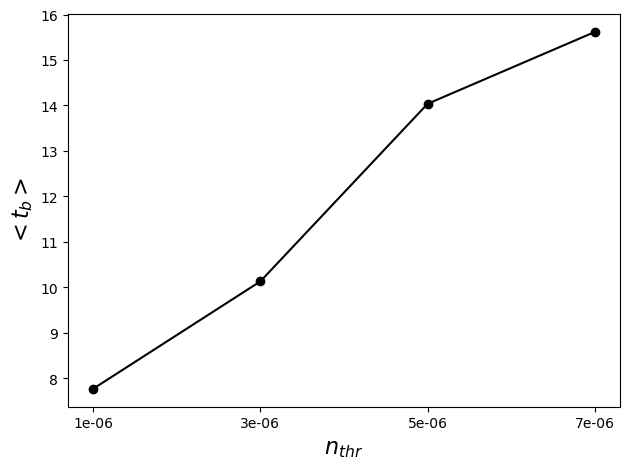

In [49]:
fig, ax = plt.subplots()
#bins = np.concatenate((np.linspace(0, 100, 15), np.linspace(85, 100, 3)))
bins = np.linspace(0, 100, 15)


ax.plot(range(len(mean_blanks)), mean_blanks,'o-', c='black',rasterized=True)
#ax.fill_between(range(len(std_blanks)), mean_blanks - p10_blanks, mean_blanks + p95_blanks, alpha = 0.4, color='black')

ax.set_xticks(range(len(mean_blanks)), noise_thresholds)
ax.set_xlabel("$n_{thr}$", fontsize=16)
ax.set_ylabel("$<t_b>$", fontsize=16)

fig.tight_layout()

fig.savefig("./plots/general/avg_blanks.pdf", bbox_inches='tight')


## Figure 3

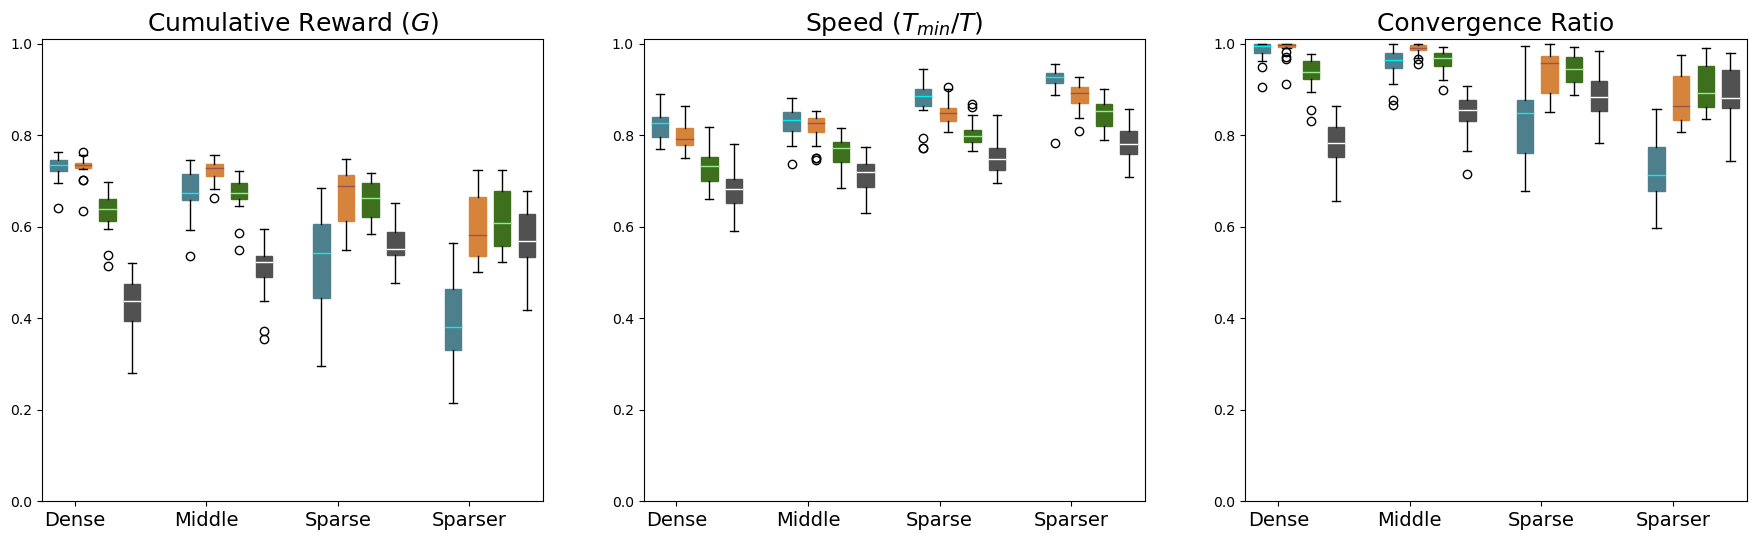

In [50]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"


creward_data, speed_data, conv_data = [],[],[]
for i in range(len(settings)):
    setting = settings[i] 
    for j in range(len(settings)):
        test_setting = settings[j]
        c_rewards = []
        speeds = []
        convergence = []

        for seed in agent_seeds:
            with open(f"{base_dir}/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
                line = f.readline().split(',')
                c_rewards.append(float(line[0]))
                speeds.append(float(line[2]))
                convergence.append(float(line[4]))
        creward_data.append(c_rewards)
        speed_data.append(speeds)
        conv_data.append(convergence)
    

num_settings = 4
num_subgroups = 4
positions = []
group_width = 1.0
subgroup_spacing = 0.75 

for i in range(num_settings):
    base = i * group_width * num_subgroups  
    positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


fig, ax = plt.subplots(1, 3, figsize=(22, 6))
b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


#print(len(b1), b1)

for i in range(len(b1['boxes'])):
    b1['boxes'][i].set_color(box_colors[i % 4])
    b1['medians'][i].set_color(median_colors[i % 4])
    b2['boxes'][i].set_color(box_colors[i % 4])
    b2['medians'][i].set_color(median_colors[i % 4])
    b3['boxes'][i].set_color(box_colors[i % 4])
    b3['medians'][i].set_color(median_colors[i % 4])

xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
for i in range(len(ax)):
    ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
ax[2].set_title("Convergence Ratio", fontsize=18)


ax[0].set_ylim([0.0, 1.01])
ax[1].set_ylim([0.0, 1.01])
ax[2].set_ylim([0.0, 1.01])

fig.savefig(f"{out_path}/performance/performance.pdf", bbox_inches='tight')


### Last detection position

In [51]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
test_settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/single_Q"


last_detections = { setting : [[] for _ in range(len(settings))] for setting in settings}


for test_setting in test_settings:
  for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
      with open(f"{base_dir}/{setting}/agent_{seed}/test/{test_setting}/failed_last_detections.log", 'r') as f:
        last_detections[test_setting][i] += [float(x.split(',')[1]) for x in f.readlines()]


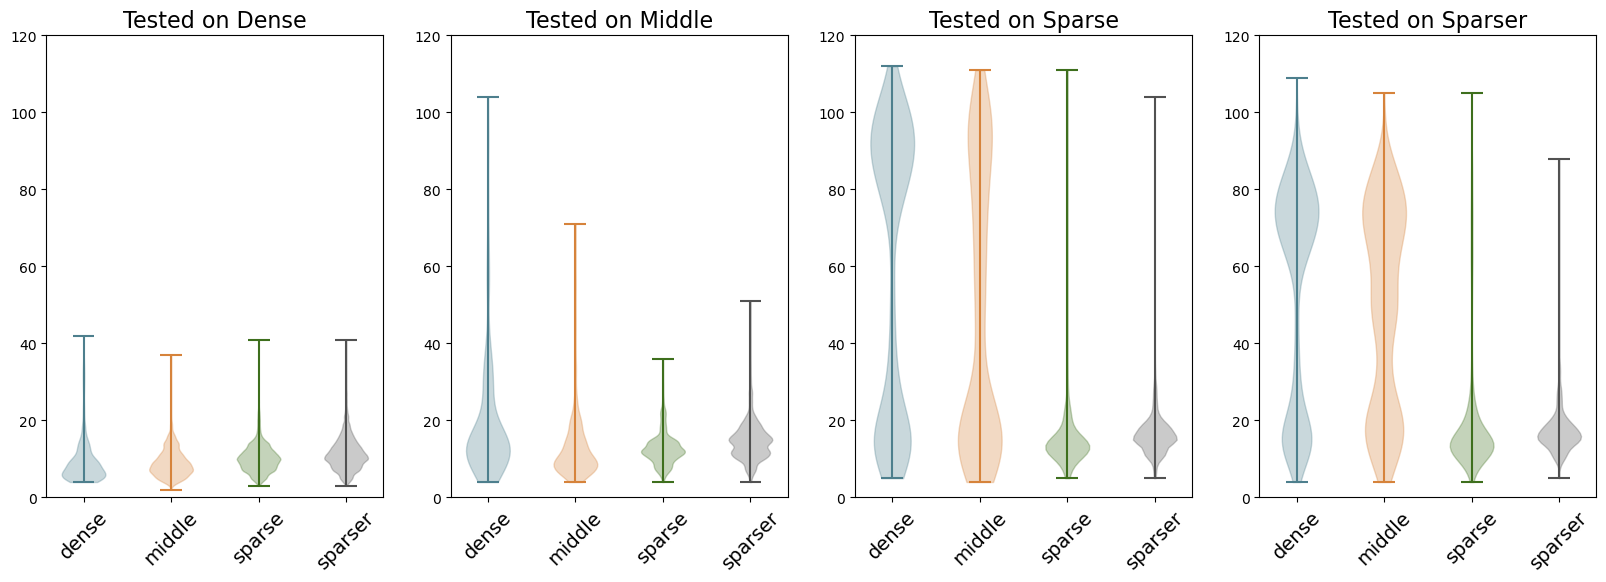

In [52]:

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for (idx, label) in zip(range(4), data_labels):
  axes[idx].set_title(f"Tested on {label}", fontsize=16)
  test_setting = label.lower()

  violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=range(len(settings)))


  for (k, e) in enumerate(violin['bodies']):
    e.set_facecolor(box_colors[k])
    e.set_edgecolor(box_colors[k])
#    e.set_medianprops({'color': box_colors[k]})

#  violin['cmedians'].set_colors(box_colors)

  # print(violin['cbars'].set_edgecolor(box_colors[idx], ))
  
  for lab in ['cbars', 'cmins', 'cmaxes']:
    
    violin[lab].set_edgecolors(box_colors)
    violin[lab].set_facecolors(box_colors)

  axes[idx].set_xticks(range(len(settings)), settings, rotation=45, fontsize=14)
  axes[idx].set_ylim([0, 120])
fig.savefig(f"{out_path}/performance/last_detection_generalization.pdf", bbox_inches='tight')



## Two-Q

In [8]:
agent = TwoQAgent(horizon=500)
out_path = './plots/two_Q'
tau = 2
taus = [2, 5, 10, 25, 50, 100, 200]

## All trajectories

plots for $Q_0$

In [5]:
Qs = [
    ('Dense',  "/storage/rando/pynav_results_new/two_Q/dense", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle', "/storage/rando/pynav_results_new/two_Q/middle", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse', "/storage/rando/pynav_results_new/two_Q/sparse", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser',"/storage/rando/pynav_results_new/two_Q/sparser", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]


In [ ]:

for tau in taus:
  for (label, main_path, color_rgb) in Qs:
      dirs= os.listdir(main_path)
      n_plots = len(dirs) // 5 # + 1
      fig, ax = plt.subplots(n_plots, 5, figsize=(10, 14))


      axes = ax.flatten()
      for i in range(len(dirs)):
          agent.load_q(f"{main_path}/{dirs[i]}/tau_{tau}/Q_stored/Qfun.npy")
          
          pos = np.array([0, 0])
          ax = axes[i]
          path = [pos.copy()]
          plot_steps = 100
          for j in range(1, plot_steps + 1):
              pos += actions[np.argmax(agent.Q[j])]
              path.append(pos.copy())

          ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
          for j in range(plot_steps): 
              ax.plot(path[j][1], path[j][0], '.', ms=1, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
              ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color=((170 - (j+1))/170) * color_rgb), rasterized=True)

          ax.set_xlim([-51, 1.0])
          ax.set_axis_off()
          ax.set_aspect('equal')
      
      if len(dirs) < len(axes):
          for i in range(len(axes) - len(dirs)):
              axes[-i-1].set_axis_off()
      fig.tight_layout()
      fig.savefig(f"{out_path}//trajectories/two_q0_policies_trained_on_{label}_tau_{tau}.pdf", bbox_inches='tight')
      plt.close(fig)
      print(f"[--] Plotted {label} [tau = {tau}]")


[--] Plotted Dense [tau = 2]
[--] Plotted Middle [tau = 2]
[--] Plotted Sparse [tau = 2]
[--] Plotted Sparser [tau = 2]
[--] Plotted Dense [tau = 5]
[--] Plotted Middle [tau = 5]
[--] Plotted Sparse [tau = 5]
[--] Plotted Sparser [tau = 5]
[--] Plotted Dense [tau = 10]
[--] Plotted Middle [tau = 10]
[--] Plotted Sparse [tau = 10]
[--] Plotted Sparser [tau = 10]


KeyboardInterrupt: 

Plots for $Q_1$

In [ ]:
for tau in [2, 5, 10, 25, 50, 100, 200]:
  for (label, main_path, color_rgb) in Qs:
      dirs= os.listdir(main_path)
      n_plots = len(dirs) // 5 # + 1
      fig, ax = plt.subplots(n_plots, 5, figsize=(10, 14))


      axes = ax.flatten()
      for i in range(len(dirs)):
          agent.load_q(f"{main_path}/{dirs[i]}/tau_{tau}/Q_stored/Qfun.npy")
          
          pos = np.array([0, 0])
          ax = axes[i]
          path = [pos.copy()]
          plot_steps = 100
          for j in range(502, 502 + plot_steps + 1):
              pos += actions[np.argmax(agent.Q[j])]
              path.append(pos.copy())

          ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
          for j in range(plot_steps): 
              ax.plot(path[j][1], path[j][0], '.', ms=1, color=((170 - (j+1))/170) * color_rgb, rasterized=True )
              ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color=((170 - (j+1))/170) * color_rgb), rasterized=True)

          ax.set_xlim([-51, 1.0])
          ax.set_axis_off()
          ax.set_aspect('equal')
      
      if len(dirs) < len(axes):
          for i in range(len(axes) - len(dirs)):
              axes[-i-1].set_axis_off()
      fig.tight_layout()
      fig.savefig(f"{out_path}//trajectories/two_q1_policies_trained_on_{label}_tau_{tau}.pdf", bbox_inches='tight')
      plt.close(fig)
      print(f"[--] Plotted {label} [tau = {tau}]")


[--] Plotted Dense [tau = 2]
[--] Plotted Middle [tau = 2]
[--] Plotted Sparse [tau = 2]
[--] Plotted Sparser [tau = 2]
[--] Plotted Dense [tau = 5]
[--] Plotted Middle [tau = 5]
[--] Plotted Sparse [tau = 5]


KeyboardInterrupt: 

## Get sample trajectories

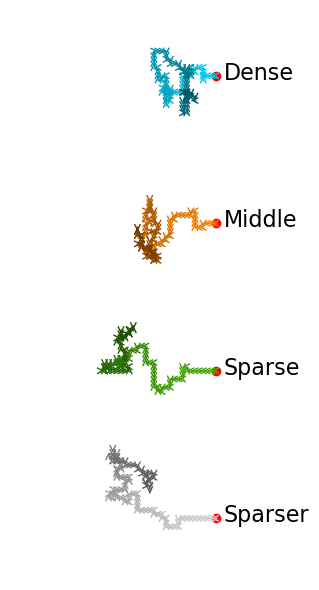

In [ ]:

Qs = [
    ('Dense',   f"/storage/rando/pynav_results_new/two_Q/dense/agent_3464/tau_{tau}/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"/storage/rando/pynav_results_new/two_Q/middle/agent_1889/tau_{tau}/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"/storage/rando/pynav_results_new/two_Q/sparse/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(1, 500):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())

    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str, rasterized=True)
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ), rasterized=True)

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()
fig.savefig(f"{out_path}/trajectories/sample_trajectories_q0_tau_{tau}.pdf", bbox_inches='tight')

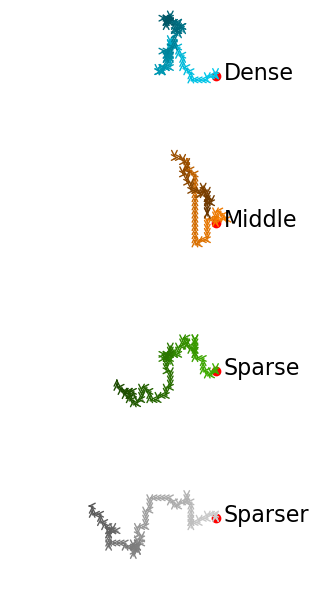

In [48]:


Qs = [
    ('Dense',   f"/storage/rando/pynav_results_new/two_Q/dense/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0x0, 0xcd, 0xf1]) / 0xff ),
    ('Middle',  f"/storage/rando/pynav_results_new/two_Q/middle/agent_1889/tau_{tau}/Q_stored/Qfun.npy", np.array([0xfc, 0x81, 0x0]) / 0xff ),
    ('Sparse',  f"/storage/rando/pynav_results_new/two_Q/sparse/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0x41, 0xb1, 0x0]) / 0xff),
    ('Sparser', f"/storage/rando/pynav_results_new/two_Q/sparser/agent_944/tau_{tau}/Q_stored/Qfun.npy", np.array([0xd2, 0xd2, 0xd2]) / 0xff),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for (i, (label, qpath, cmap_str)) in enumerate(Qs):
    agent.load_q(qpath)
    pos = np.array([0, 0])
    ax = axes[i]
    path = [pos.copy()]
    for j in range(502, 1004):
        pos += actions[np.argmax(agent.Q[j])]
        path.append(pos.copy())




    ax.plot(path[0][1], path[0][0], 'o', c='red', label='starting point')
#    colormap = cm.get_cmap(box_colors[i])
    plot_steps = 100
    for j in range(plot_steps): 
        ax.plot(path[j][1], path[j][0], '.', ms=1, color= ((170 - (j+1))/170) * cmap_str, rasterized=True)
        ax.annotate("", xytext=(path[j][1], path[j][0]), xy=(path[j+1][1], path[j+1][0]), arrowprops=dict(arrowstyle='->', color= ((170 - (j+1))/170) * cmap_str ), rasterized=True)

    ax.text(2.0, -1.0, f"{label}", fontsize=16)

    ax.set_xlim([-50, 2.0])
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_ylim([-15, 16.0])
fig.tight_layout()

fig.savefig(f"{out_path}/trajectories/sample_trajectories_q1_tau_{tau}.pdf", bbox_inches='tight')

## Performance

In [9]:

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"


for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  for i in range(len(settings)):
      setting = settings[i] 
      for j in range(len(settings)):
          test_setting = settings[j]
          c_rewards = []
          speeds = []
          convergence = []

          for seed in agent_seeds:

              with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
                  line = f.readline().split(',')
                  c_rewards.append(float(line[0]))
                  speeds.append(float(line[2]))
                  convergence.append(float(line[4]))
          creward_data.append(c_rewards)
          speed_data.append(speeds)
          conv_data.append(convergence)
      

  num_settings = 4
  num_subgroups = 4
  positions = []
  group_width = 1.0
  subgroup_spacing = 0.75 

  for i in range(num_settings):
      base = i * group_width * num_subgroups  
      positions += [base + j * subgroup_spacing for j in range(num_subgroups)]


  fig, ax = plt.subplots(1, 3, figsize=(22, 6))
  b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
  b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
  b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


  #print(len(b1), b1)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[i % 4])
      b1['medians'][i].set_color(median_colors[i % 4])
      b2['boxes'][i].set_color(box_colors[i % 4])
      b2['medians'][i].set_color(median_colors[i % 4])
      b3['boxes'][i].set_color(box_colors[i % 4])
      b3['medians'][i].set_color(median_colors[i % 4])

  xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  for i in range(len(ax)):
      ax[i].set_xticks(ticks=xticks, labels=data_labels, fontsize=14)

  ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
  ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
  ax[2].set_title("Convergence Ratio", fontsize=18)

  ax[0].set_ylim([0.0, 1.01])
  ax[1].set_ylim([0.0, 1.01])
  ax[2].set_ylim([0.0, 1.01])
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"{out_path}/performance/performance_tau_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)


[--] Plotted for tau = 2
[--] Plotted for tau = 5
[--] Plotted for tau = 10
[--] Plotted for tau = 25
[--] Plotted for tau = 50
[--] Plotted for tau = 100
[--] Plotted for tau = 200


## Used fraction

In [45]:
Q_usage = []
taus = [2, 5, 10, 25, 50, 100]

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"



for setting in settings:
  Qmin_usage, Qplus_usage = [], []
  for tau in taus:
    minus_usage, plus_usage = [], []
    for seed in agent_seeds:
      with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_list.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
          splitted = line.split(',')
          # if int(splitted[0]) == 0:
          #   continue
          minus_usage.append(float(splitted[1]))
          plus_usage.append(float(splitted[2]))
    Qmin_usage.append(np.sum(minus_usage))
    Qplus_usage.append(np.sum(plus_usage))
    
  Qmin_usage = np.array(Qmin_usage)
  Qplus_usage = np.array(Qplus_usage)
  Q_usage.append(Qmin_usage / Qplus_usage)
        

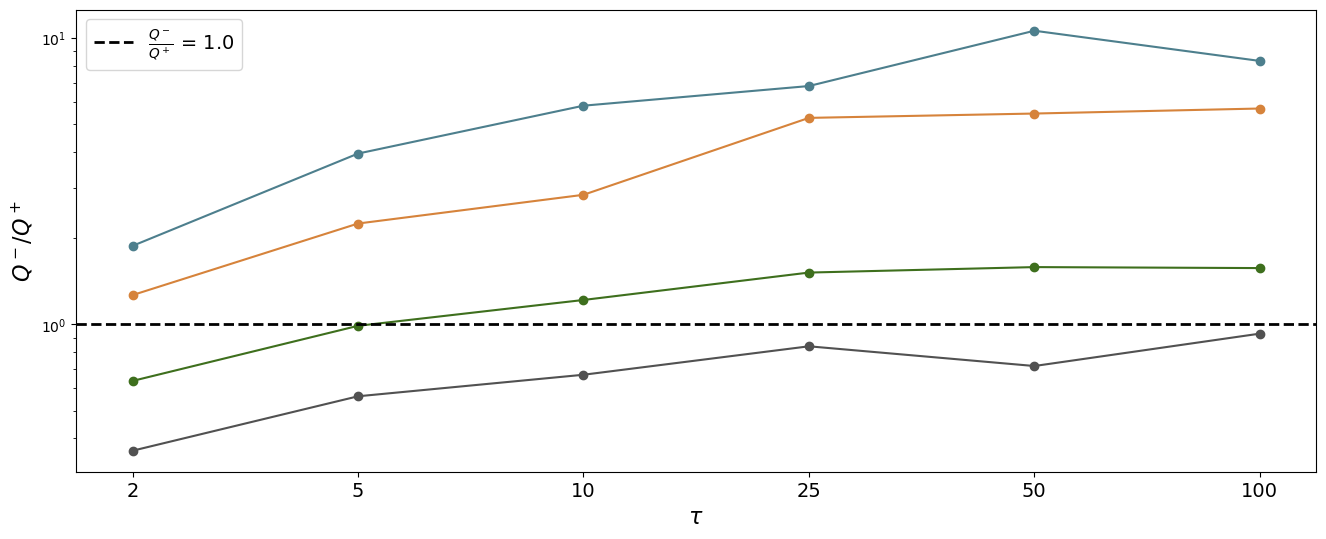

In [46]:


fig, ax = plt.subplots(1, 1, figsize=(16, 6))

for i in range(len(settings)):
  ax.plot(Q_usage[i], 'o-', color=box_colors[i], rasterized=True)

ax.set_yscale('log')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='$\\frac{Q^-}{Q^+}$ = 1.0', lw=2, rasterized=True)
ax.set_xticks(range(len(taus)), taus, fontsize=14)
ax.set_xlabel("$\\tau$", fontsize=16)
ax.set_ylabel("$Q^-$/$Q^+$", fontsize=16)

ax.legend(fontsize=14)

In [31]:
taus = [2, 5, 10, 25, 50, 100]

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"



Q_settings = []
for setting in settings:
  Qmin_usage, Qplus_usage = [], []
  Q = []
  Q_taus = []
  for tau in taus:
    minus_usage, plus_usage = [], []
    Q_agents = []
    for seed in agent_seeds:
      with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_list.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
          splitted = line.split(',')
          # if int(splitted[0]) == 0:
          #   continue
          minus_usage.append(float(splitted[1]))
          plus_usage.append(float(splitted[2]))
      Q_m, Q_p = np.sum(minus_usage), np.sum(plus_usage)
      Q_agents.append(Q_m / Q_p)
    # Q_agents contains Q_m / Q_p for each agent at given tau for the given setting
    Q_taus.append(Q_agents)
  Q_settings.append(Q_taus)

6 6
6 6
6 6
6 6


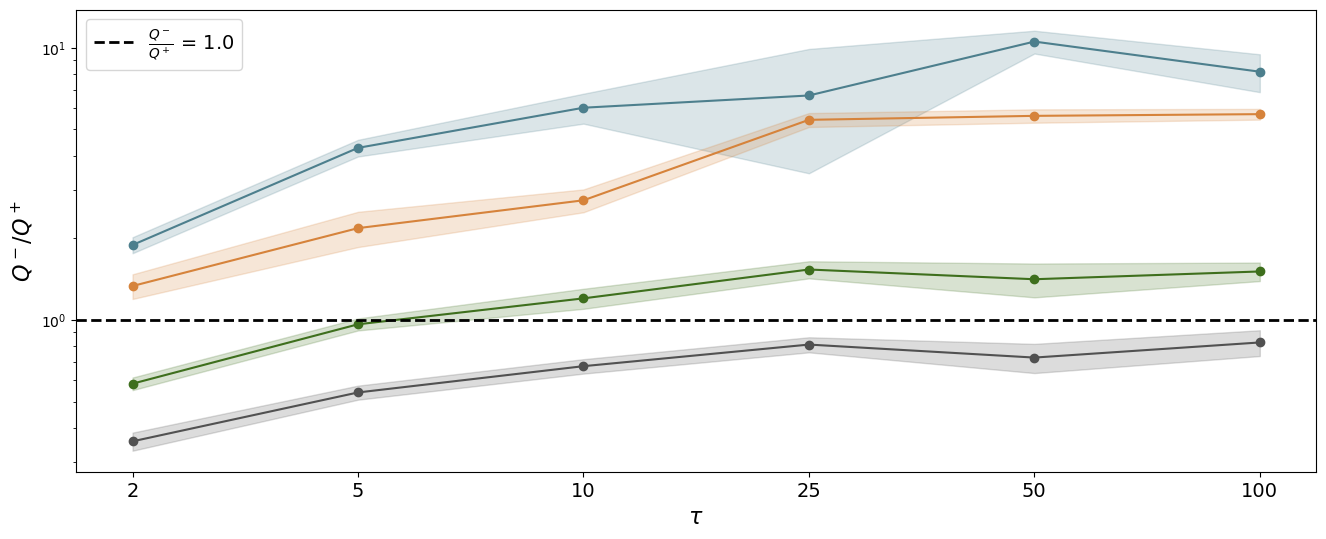

In [32]:


fig, ax = plt.subplots(1, 1, figsize=(16, 6))

for i in range(len(settings)):
  print(len(Q_settings[i]), len(taus))
#  ax.boxplot(Q_settings[i], positions=range(len(taus)), patch_artist=True, showfliers=False, medianprops={'color': median_colors[i]})
  mu, std = np.array([np.mean(Q_settings[i][j]) for j in range(len(taus)) ]), np.array([np.std(Q_settings[i][j]) for j in range(len(taus)) ])
  ax.plot(mu, 'o-', color=box_colors[i], rasterized=True)
  ax.fill_between(range(len(taus)), mu - std, mu + std, color=box_colors[i], alpha=0.2, rasterized=True)
#  ax.plot([np.std(Q_settings[i][j]) for j in range(len(taus)) ], 'o-', color=box_colors[i], rasterized=True)

ax.set_yscale('log')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='$\\frac{Q^-}{Q^+}$ = 1.0', lw=2, rasterized=True)
ax.set_xticks(range(len(taus)), taus, fontsize=14)
ax.set_xlabel("$\\tau$", fontsize=16)
ax.set_ylabel("$Q^-$/$Q^+$", fontsize=16)

ax.legend(fontsize=14)

## 1Q vs 2Q Native

In [ ]:
base_dir = "/storage/rando/pynav_results_new"
opt_taus = [2, 2, 5, 25]
#for (tr_idx, setting) in enumerate(['dense', 'middle', 'sparse', 'sparser']):
fig, axes = plt.subplots(4, 3, figsize=(20, 12))
for setting_idx, setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
  ax = axes[setting_idx]
  creward_data, speed_data, conv_data = [],[],[]
  c_rewards = []
  speeds = []
  convergence = []

  tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

  for seed in agent_seeds:
    with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)

  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[setting_idx]}/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)


#  fig.suptitle(f"Trained on {setting}", fontsize=20)
  b1 = ax[0].boxplot(creward_data,  patch_artist=True)
  b2 = ax[1].boxplot(speed_data,  patch_artist=True)
  b3 = ax[2].boxplot(conv_data,  patch_artist=True)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[setting_idx])
      b1['medians'][i].set_color(median_colors[setting_idx])
      b2['boxes'][i].set_color(box_colors[setting_idx])
      b2['medians'][i].set_color(median_colors[setting_idx])
      b3['boxes'][i].set_color(box_colors[setting_idx])
      b3['medians'][i].set_color(median_colors[setting_idx])

  for i in range(len(ax)):
      ax[i].set_xticks(ticks=range(1, 3), labels=['1Q', '2Q (trained)'], fontsize=14)
#  ax[0].set_ylim([0.4, 0.8])
  if setting_idx == 0:
    ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
    ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
    ax[2].set_title("Convergence Ratio", fontsize=18)

fig.tight_layout()
fig.savefig(f"{out_path}/performance/1q_vs_2q_native.pdf", bbox_inches='tight')
plt.close(fig)


## 1Q vs 2Q vs 2Q (heur)

In [ ]:
base_dir = "/storage/rando/pynav_results_new"
opt_taus = [2, 2, 5, 25]
#for (tr_idx, setting) in enumerate(['dense', 'middle', 'sparse', 'sparser']):
fig, axes = plt.subplots(4, 3, figsize=(20, 12))
for setting_idx, setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
  ax = axes[setting_idx]
  creward_data, speed_data, conv_data = [],[],[]
  c_rewards = []
  speeds = []
  convergence = []

  tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

  for seed in agent_seeds:
    with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)

  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[setting_idx]}/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)

  c_rewards = []
  speeds = []
  convergence = []
  for seed in agent_seeds:
    with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_25/test/{setting}/test_summary.log", 'r') as f:
      splitted = f.readline().split(',')
      c_rewards.append(float(splitted[0]))
      speeds.append(float(splitted[2]))
      convergence.append(float(splitted[4]))

  creward_data.append(c_rewards)
  speed_data.append(speeds)
  conv_data.append(convergence)


#  fig.suptitle(f"Trained on {setting}", fontsize=20)
  b1 = ax[0].boxplot(creward_data,  patch_artist=True)
  b2 = ax[1].boxplot(speed_data,  patch_artist=True)
  b3 = ax[2].boxplot(conv_data,  patch_artist=True)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[setting_idx])
      b1['medians'][i].set_color(median_colors[setting_idx])
      b2['boxes'][i].set_color(box_colors[setting_idx])
      b2['medians'][i].set_color(median_colors[setting_idx])
      b3['boxes'][i].set_color(box_colors[setting_idx])
      b3['medians'][i].set_color(median_colors[setting_idx])

  for i in range(len(ax)):
      ax[i].set_xticks(ticks=range(1, 4), labels=['1Q', '2Q (trained)', '2Q (heuristic)'], fontsize=14)
#  ax[0].set_ylim([0.4, 0.8])
  if setting_idx == 0:
    ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
    ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
    ax[2].set_title("Convergence Ratio", fontsize=18)

fig.tight_layout()
fig.savefig(f"{out_path}/performance/1q_vs_2q_2q_nat_native.pdf", bbox_inches='tight')
plt.close(fig)


## Position of last detection on failures

In [36]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"

for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  fig, axes = plt.subplots(2,2, figsize=(12, 6))
  axes = axes.flatten()
  for i in range(len(settings)):
      ax = axes[i]
      setting = settings[i] 
      x_pos, y_pos = [], []
      Q_num = []
      for seed in agent_seeds:
          with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/failed_last_detections.log", 'r') as f:
              for line in f.readlines():
                  splitted = line.split(',')
                  y_pos.append(int(splitted[0]))
                  x_pos.append(int(splitted[1]))
                  Q_num.append(int(splitted[2]))
      new_data = data_environments[noise_thresholds[i]]
      ax.set_title(f"Trained and Test on {setting}")
      ax.imshow(np.log10(new_data[100, :, :]), origin='lower')
      for j in range(len(y_pos)):
          if Q_num[j] == 0:
              ax.plot(x_pos[j], y_pos[j], 'o', c='red')
          else:        
              ax.plot(x_pos[j], y_pos[j], 'o', c='blue')
  fig.tight_layout()
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"{out_path}/performance/failed_positions_tau_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)

dense 1762
middle 1817
sparse 1849
sparser 2389
[--] Plotted for tau = 5
dense 2269
middle 1198
sparse 1314
sparser 1382
[--] Plotted for tau = 10
dense 3342
middle 805
sparse 1471
sparser 1876
[--] Plotted for tau = 25
dense 1076
middle 1035
sparse 1282
sparser 1412
[--] Plotted for tau = 50
dense 1719
middle 1887
sparse 1046
sparser 934
[--] Plotted for tau = 100
dense 1357
middle 1537
sparse 1509
sparser 1574
[--] Plotted for tau = 200


## Q used map

In [6]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"


for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  fig, axes = plt.subplots(2,2, figsize=(12, 6))
  axes = axes.flatten()
  for i in range(len(settings)):
      ax = axes[i]
      setting = settings[i] 
      Q_v = {}
      Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
      for seed in agent_seeds:
          with open(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_map.log", 'r') as f:
              for line in f.readlines():
                  splitted = line.split(',')
                  
                  y_pos = int(splitted[0])
                  x_pos = int(splitted[1])
                  if y_pos not in Q_v:
                      Q_v[y_pos] = {}
                  if x_pos not in Q_v[y_pos]:
                      Q_v[y_pos][x_pos] = []
                  Q_v[y_pos][x_pos].append(float(splitted[2]))
      for y_pos, xmap in Q_v.items():
          for x_pos, vals in xmap.items():
              Q_map[y_pos, x_pos] = np.mean(vals)

      new_data = data_environments[noise_thresholds[i]]
      ax.set_title(f"Trained and Test on {setting}")
      im =ax.imshow(Q_map, origin='lower', vmin=0.0, vmax=1.0)
  fig.tight_layout()
  fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')    
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"./plots/two_Q/performance/two_q_usage_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)

/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 2


/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 5


/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 10


... (4 outputs left out)

/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 100


/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_4147627/1426791228.py:14: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 200


## Changing tau

In [7]:
base_dir = "/storage/rando/pynav_results_new"

for setting in ['dense', 'middle', 'sparse', 'sparser']:
  fig, axes = plt.subplots(4, 3, figsize=(20, 12))
  for setting_idx, test_setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
    ax = axes[setting_idx]
    creward_data, speed_data, conv_data = [],[],[]
    c_rewards = []
    speeds = []
    convergence = []

    tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

    for seed in agent_seeds:
      with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
        splitted = f.readline().split(',')
        c_rewards.append(float(splitted[0]))
        speeds.append(float(splitted[2]))
        convergence.append(float(splitted[4]))

    creward_data.append(c_rewards)
    speed_data.append(speeds)
    conv_data.append(convergence)

    for tau in taus:
      c_rewards = []
      speeds = []
      convergence = []
      for seed in agent_seeds:
        with open(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
          splitted = f.readline().split(',')
          c_rewards.append(float(splitted[0]))
          speeds.append(float(splitted[2]))
          convergence.append(float(splitted[4]))

      creward_data.append(c_rewards)
      speed_data.append(speeds)
      conv_data.append(convergence)


    fig.suptitle(f"Trained on {setting}", fontsize=20)
    b1 = ax[0].boxplot(creward_data,  patch_artist=True)
    b2 = ax[1].boxplot(speed_data,  patch_artist=True)
    b3 = ax[2].boxplot(conv_data,  patch_artist=True)

    for i in range(len(b1['boxes'])):
        b1['boxes'][i].set_color(box_colors[setting_idx])
        b1['medians'][i].set_color(median_colors[setting_idx])
        b2['boxes'][i].set_color(box_colors[setting_idx])
        b2['medians'][i].set_color(median_colors[setting_idx])
        b3['boxes'][i].set_color(box_colors[setting_idx])
        b3['medians'][i].set_color(median_colors[setting_idx])

    for i in range(len(ax)):
        ax[i].set_xticks(ticks=range(1, len(taus) + 2), labels=tick_labels, fontsize=14)
    ax[0].set_ylim([0.3, 0.8])
    if setting_idx == 0:
      ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
      ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
      ax[2].set_title("Convergence Ratio", fontsize=18)

  fig.tight_layout()
  fig.savefig(f"{out_path}/performance/tau_comparison_{setting}.pdf", bbox_inches='tight')
  plt.close(fig)


## Characterization

In [6]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"
tau = 2
tr_max_void = [[], [], [], []]
tr_mean_void = [[], [], [], []]

tr_max_steps = [[], [], [], []]
tr_mean_steps = [[], [], [], []]


tr_max_state =  [[], [], [], []]
tr_mean_state =  [[], [], [], []]

delta = 500

opt_taus = [2, 2, 5, 25]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        with open(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/training.log", 'r') as f:
            num_void_steps, num_steps = [], []
            for line in f.readlines()[-delta:]:
                num_void_steps.append(int(line.split(',')[-1]))
                num_steps.append(int(line.split(',')[-2]))
            
            tr_max_void[i].append(np.max(num_void_steps))
            tr_mean_void[i].append(np.mean(num_void_steps))
            tr_max_steps[i].append(np.max(num_steps))
            tr_mean_steps[i].append(np.mean(num_steps))


        tr_states = np.load(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/training_max_void_lengths.npy")
        tr_max_state[i].append(np.max(tr_states[-delta:]))
        tr_mean_state[i].append(np.mean(tr_states[-delta:]))
    print(f"[--] Completed setting {setting}")



[--] Completed setting dense
[--] Completed setting middle
[--] Completed setting sparse
[--] Completed setting sparser


In [7]:

metric_names = ["mean_state", "max_state", "mean_void", "max_void", "entire_traj"]
metrics = [tr_mean_state, tr_max_state, tr_mean_void, tr_max_void, 500]

## Surge Length

In [10]:

surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=0, count_to=502))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


ax.set_title("Surge Length ($Q_0$)")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/surge_length_q0_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


In [97]:

surge_length = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length[i].append(compute_surge_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=502, count_to=1004))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(surge_length, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Surge Length ($Q_1$)")
ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/surge_length_q1_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


## Search Length

In [98]:
for met,met_name in zip(metrics, metric_names):

  search_len = [[], [], [], []]
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) ) 
          else:
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(search_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Search Length (Upwind): $Q_0$ {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)

  fig.savefig(f"{out_path}/characterization/search_length_{met_name}_q0_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


In [99]:
for met,met_name in zip(metrics, metric_names):

  search_len = [[], [], [], []]
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
          else:
            search_len[i].append(compute_search_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502 ) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(search_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Search Length (Upwind): $Q_1$ {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)

  fig.savefig(f"{out_path}/characterization/search_length_{met_name}_q1_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


## Cast-Width

In [100]:


for met,met_name in zip(metrics, metric_names):
  cast_width = [[], [], [], []]

  for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):
            if met_name == 'entire_traj':
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0) ) 
            else:
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 



  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(cast_width, patch_artist=True)

  for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


  ax.set_title(f"Cast width ($Q_0$) : {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/cast_width_{met_name}_q0_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)
			




In [101]:

for met,met_name in zip(metrics, metric_names):
  cast_width = [[], [], [], []]

  for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):
            if met_name == 'entire_traj':
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502) ) 
            else:
              cast_width[i].append(compute_cast_width(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502 ) ) 



  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(cast_width, patch_artist=True)

  for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])


  ax.set_title(f"Cast width ($Q_1$) : {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/cast_width_{met_name}_q1_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)




## Backtracking Length

In [102]:
for met,met_name in zip(metrics, metric_names):

  bck_len = [[], [], [], []]

  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) ) 
          else:
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]), count_from=0 ) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(bck_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Backtracking Length ($Q_0$): {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}_q0_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)



In [103]:
for met,met_name in zip(metrics, metric_names):

  bck_len = [[], [], [], []]

  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
          else:
            bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502) ) 


  fig, ax = plt.subplots(1, 1, figsize=(12, 6))

  b = ax.boxplot(bck_len, patch_artist=True)
  for i in range(len(b['boxes'])):
      b['boxes'][i].set_color(box_colors[i])
      b['medians'][i].set_color(median_colors[i])

  ax.set_title(f"Backtracking Length ($Q_1$): {met_name}")
  ax.set_xticklabels(data_labels, fontsize=14)
  fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}_q1_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)



## Backtracking Init Time

In [104]:



backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, acc_steps ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time ($Q_0$)")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/backtracking_init_time_q0_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


In [105]:


backtrack_init = [[], [], [], []]
acc_steps = 3
for (i, setting) in enumerate(settings):
    for (j, seed) in enumerate(agent_seeds):

        # entire trajectory
        backtrack_init[i].append(compute_backtracking_init_time(f"{base_dir}/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, acc_steps, count_from=502 ))


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

b = ax.boxplot(backtrack_init, patch_artist=True)
for i in range(len(b['boxes'])):
    b['boxes'][i].set_color(box_colors[i])
    b['medians'][i].set_color(median_colors[i])

ax.set_title("Backtracking Init Time ($Q_1$)")

ax.set_xticklabels(data_labels, fontsize=14)
fig.savefig(f"{out_path}/characterization/backtracking_init_time_q1_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


## Comparison using Single Q

In [106]:

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_Q"

tau = 2
last_detections = {setting : [[] for _ in range(3)] for setting in settings}


for (tr_idx, train_setting) in enumerate(settings):

  for setting in settings:
      for seed in agent_seeds:
            with open(f"{base_dir}/{train_setting}/agent_{seed}/tau_{opt_taus[tr_idx]}/test/{setting}/failed_last_detections.log", 'r') as f:
                last_detections[setting][0] += [float(x.split(',')[1]) for x in f.readlines()]

            for i in [0, 1]:       
                with open(f"{base_dir}/{train_setting}/agent_{seed}/tau_{opt_taus[tr_idx]}/test/{setting}/only_Q_{i}/failed_last_detections.log", 'r') as f:
                    last_detections[setting][i + 1] += [float(x.split(',')[1]) for x in f.readlines()]





  fig, axes = plt.subplots(1, 4, figsize=(20, 6))

  fig.suptitle(f"Trained in {train_setting}", fontsize=20)
  for (idx, label) in zip(range(4), data_labels):

      axes[idx].set_title(f"Tested in {label}", fontsize=16)
      violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=[0, 1, 2])


      for e in violin['bodies']:
          e.set_facecolor(box_colors[idx])
          e.set_edgecolor(box_colors[idx])

      for lab in ['cbars', 'cmins', 'cmaxes']:
          violin[lab].set_edgecolor(box_colors[idx])
          violin[lab].set_facecolor(box_colors[idx])
          
  #    axes[idx].set_ylim([0, 30])
      axes[idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'])
  fig.savefig(f"./plots/two_Q/single_vs_two/failed_positions_vs_single_opt_tau_trained_{train_setting}.pdf", bbox_inches='tight')

  plt.close(fig)
  

FileNotFoundError: [Errno 2] No such file or directory: '/storage/rando/pynav_results_new/two_Q/dense/agent_1259/tau_2/test/dense/only_Q_0/failed_last_detections.log'

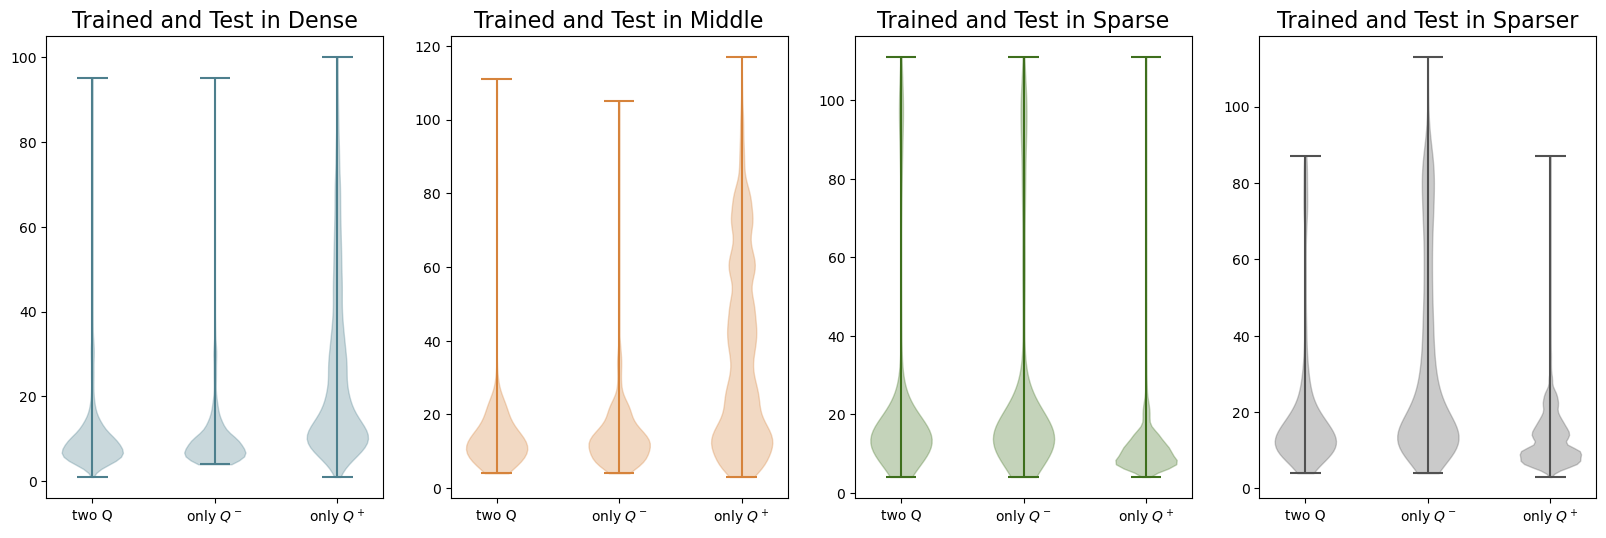

In [ ]:



fig, axes = plt.subplots(1, 4, figsize=(20, 6))

fig.suptitle(f"Trained in {train_setting} (tau = {tau})", fontsize=20)
for (idx, label) in zip(range(4), data_labels):

    axes[idx].set_title(f"Trained and Test in {label}", fontsize=16)
    violin = axes[idx].violinplot(last_detections[data_labels[idx].lower()], positions=[0, 1, 2])


    for e in violin['bodies']:
        e.set_facecolor(box_colors[idx])
        e.set_edgecolor(box_colors[idx])

    for lab in ['cbars', 'cmins', 'cmaxes']:
        violin[lab].set_edgecolor(box_colors[idx])
        violin[lab].set_facecolor(box_colors[idx])
        
#    axes[idx].set_ylim([0, 30])
    axes[idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'])
fig.savefig(f"./plots/two_Q/single_vs_two/failed_positions_vs_single_tau_{tau}.pdf", bbox_inches='tight')

plt.close(fig)

In [11]:

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']


for tr_setting in settings:
  creward = {setting : [[] for _ in range(3)] for setting in settings}
  speed = {setting : [[] for _ in range(3)] for setting in settings}
  convergence = {setting : [[] for _ in range(3)] for setting in settings}

  for setting in settings:
      for seed in agent_seeds:
            with open(f"{base_dir}/{tr_setting}/agent_{seed}/tau_{tau}/test/{setting}/test_summary.log", 'r') as f:
              splitted = f.readline().split(',')
              creward[setting][0].append(float(splitted[0]))
              speed[setting][0].append(float(splitted[2]))
              convergence[setting][0].append(float(splitted[4]))

            for i in [0, 1]:       
                with open(f"{base_dir}/{tr_setting}/agent_{seed}/tau_{tau}/test/{setting}/only_Q_{i}/test_summary.log", 'r') as f:
                  splitted = f.readline().split(',')
                  creward[setting][i + 1].append(float(splitted[0]))
                  speed[setting][i + 1].append(float(splitted[2]))
                  convergence[setting][i + 1].append(float(splitted[4]))



  fig, axes = plt.subplots(3, 4, figsize=(20, 10))

  for (idx, label) in zip(range(4), data_labels):
    b1 = axes[0, idx].boxplot(creward[data_labels[idx].lower()], positions=range(3), patch_artist=True)
    b2 = axes[1, idx].boxplot(speed[data_labels[idx].lower()], positions=range(3), patch_artist=True)
    b3 = axes[2, idx].boxplot(convergence[data_labels[idx].lower()], positions=range(3), patch_artist=True)

    for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[idx])
      b1['medians'][i].set_color(median_colors[idx])
      b2['boxes'][i].set_color(box_colors[idx])
      b2['medians'][i].set_color(median_colors[idx])
      b3['boxes'][i].set_color(box_colors[idx])
      b3['medians'][i].set_color(median_colors[idx])

    axes[0, idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'], fontsize=14)
    axes[1, idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'], fontsize=14)
    axes[2, idx].set_xticks(range(3), ['two Q', 'only $Q^-$', 'only $Q^+$'], fontsize=14)
  axes[0, 0].set_ylabel("Cumulative Reward", fontsize=16)
  axes[1, 0].set_ylabel("Speed ($T_{min} / T$)", fontsize=16)
  axes[2, 0].set_ylabel("Convergence", fontsize=16)
  fig.suptitle(f"Trained on {tr_setting}",fontsize=22)
  fig.tight_layout()
  fig.savefig(f"./plots/two_Q/single_vs_two/performance_comparison_vs_single_tau_{tau}_trained_{tr_setting}.pdf", bbox_inches='tight')
  plt.close(fig)


FileNotFoundError: [Errno 2] No such file or directory: '/storage/rando/pynav_results_new/two_Q/dense/agent_1259/tau_2/test/dense/only_Q_0/test_summary.log'

## Geometry Comparison (Two Q, Q-, Q+, single Q)

In [12]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new"

tau = 5

### Surge Length

In [16]:

surge_length_single = [[], [], [], []]
surge_length_Q0 = [[], [], [], []]
surge_length_Q1 = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length_single[i].append(compute_surge_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=0, count_to=502))
        surge_length_Q0[i].append(compute_surge_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=0, count_to=502))
        surge_length_Q1[i].append(compute_surge_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", num_accepted_steps=3, count_from=502, count_to=1024))


surge_lengths = [surge_length_single, surge_length_Q0, surge_length_Q1]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes = axes.flatten()
for i in range(len(axes)):
  ax = axes[i]
  b = ax.boxplot(surge_lengths[i], patch_artist=True)
#  b2 = ax.boxplot(surge_length_Q1, patch_artist=True)
  for j in range(len(b['boxes'])):
      b['boxes'][j].set_color(box_colors[j])
      b['medians'][j].set_color(median_colors[j])

  if i > 0:
    if i == 1:
      ax.set_title("$Q^-$")
    else:
      ax.set_title(f"$Q^+$")
  else:
    ax.set_title("1Q")
  ax.set_xticklabels(data_labels, fontsize=14)
  ax.set_ylim([-0.1, 30])
fig.savefig(f"{out_path}/characterization/surge_length_2qvs1q_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


### Backtracking init time

In [23]:

surge_length_single = [[], [], [], []]
surge_length_Q0 = [[], [], [], []]
surge_length_Q1 = [[], [], [], []]

for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
        surge_length_single[i].append(compute_backtracking_init_time(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 502, 2))
        surge_length_Q0[i].append(compute_backtracking_init_time(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, 2, count_from=1))
        surge_length_Q1[i].append(compute_backtracking_init_time(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, 2, count_from=502))


surge_lengths = [surge_length_single, surge_length_Q0, surge_length_Q1]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes = axes.flatten()
for i in range(len(axes)):
  ax = axes[i]
  b = ax.boxplot(surge_lengths[i], patch_artist=True)
#  b2 = ax.boxplot(surge_length_Q1, patch_artist=True)
  for j in range(len(b['boxes'])):
      b['boxes'][j].set_color(box_colors[j])
      b['medians'][j].set_color(median_colors[j])

  # if i > 0:
  #   ax.set_title(f"Backtracking init time ($Q_{i - 1}$)")
  # else:
  #   ax.set_title("Backtracking init time (Single Q)")
  if i > 0:
    if i == 1:
      ax.set_title("$Q^-$")
    else:
      ax.set_title(f"$Q^+$")
  else:
    ax.set_title("1Q")
  
  ax.set_xticklabels(data_labels, fontsize=14)
  ax.set_ylim([-0.5, 350])
fig.savefig(f"{out_path}/characterization/backtracking_init_time_2qvs1q_opt_tau.pdf", bbox_inches='tight')
plt.close(fig)


## Other metrics

In [24]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
base_dir = "/storage/rando/pynav_results_new/"

metric_names = ['tr_max_void', 'tr_mean_void', 'tr_max_steps', 'tr_mean_steps', 'tr_max_state', 'tr_mean_state']
agent_names = ['single_Q', 'two_Q']


metrics = {name: {metric: [[], [], [], []] for metric in metric_names} for name in agent_names}


delta = 500
for agent_name in agent_names:
  for (i, setting) in enumerate(settings):
    for seed in agent_seeds:
      if agent_name == 'single_Q':
        agent_dir = f"{base_dir}/single_Q/{setting}/agent_{seed}"
      else:
        agent_dir = f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}"

      with open(f"{agent_dir}/training.log", 'r') as f:
          num_void_steps, num_steps = [], []
          for line in f.readlines()[-delta:]:
              num_void_steps.append(int(line.split(',')[-1]))
              num_steps.append(int(line.split(',')[-2]))
      metrics[agent_name]['tr_max_void'][i].append(np.max(num_void_steps))
      metrics[agent_name]['tr_mean_void'][i].append(np.mean(num_void_steps))
      metrics[agent_name]['tr_max_steps'][i].append(np.max(num_steps))
      metrics[agent_name]['tr_mean_steps'][i].append(np.mean(num_steps))              

      tr_states = np.load(f"{agent_dir}/training_max_void_lengths.npy")
      metrics[agent_name]['tr_max_state'][i].append(np.max(tr_states[-delta:]))
      metrics[agent_name]['tr_mean_state'][i].append(np.mean(tr_states[-delta:]))
          

    print(f"[{agent_name}] Completed setting {setting}")



[single_Q] Completed setting dense
[single_Q] Completed setting middle
[single_Q] Completed setting sparse
[single_Q] Completed setting sparser
[two_Q] Completed setting dense
[two_Q] Completed setting middle
[two_Q] Completed setting sparse
[two_Q] Completed setting sparser


### Search Length

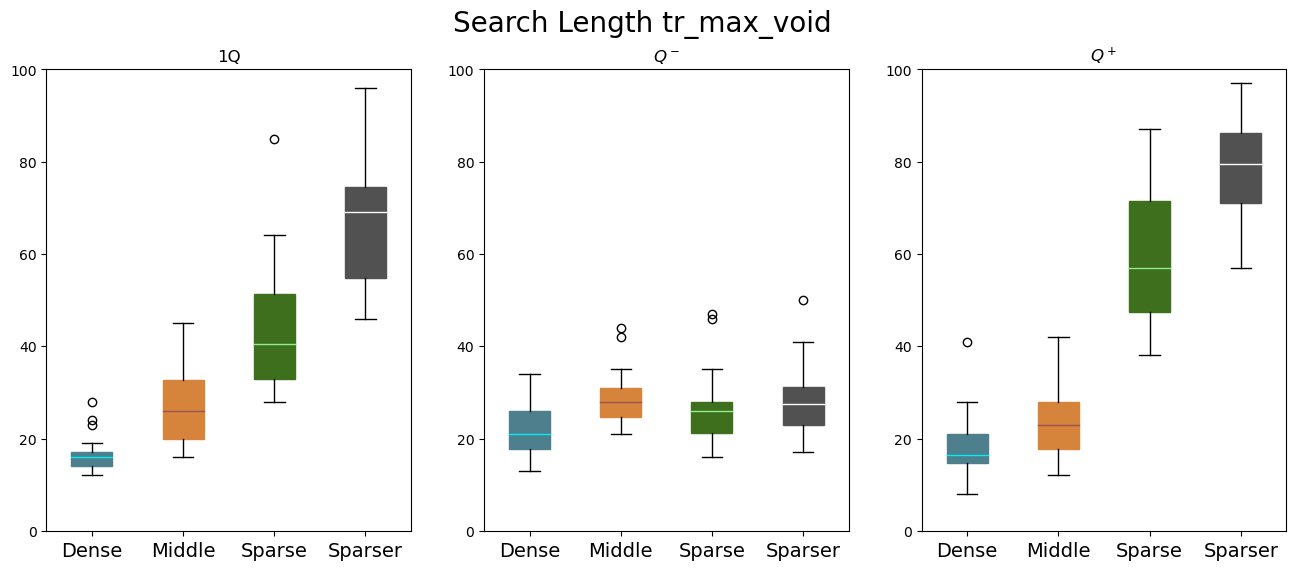

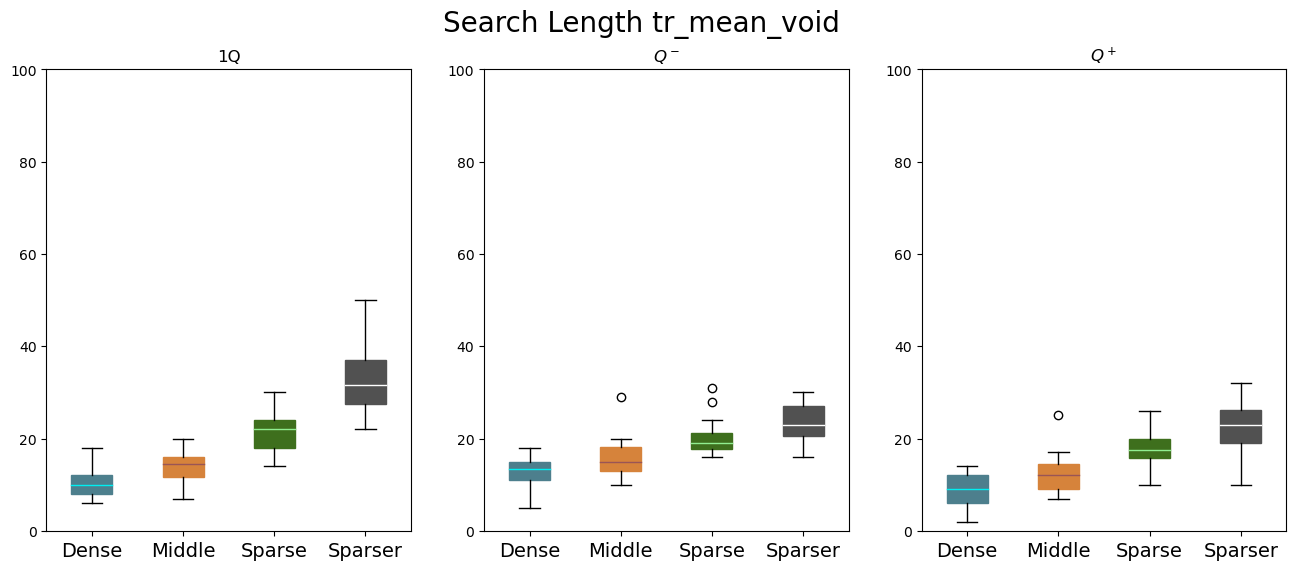

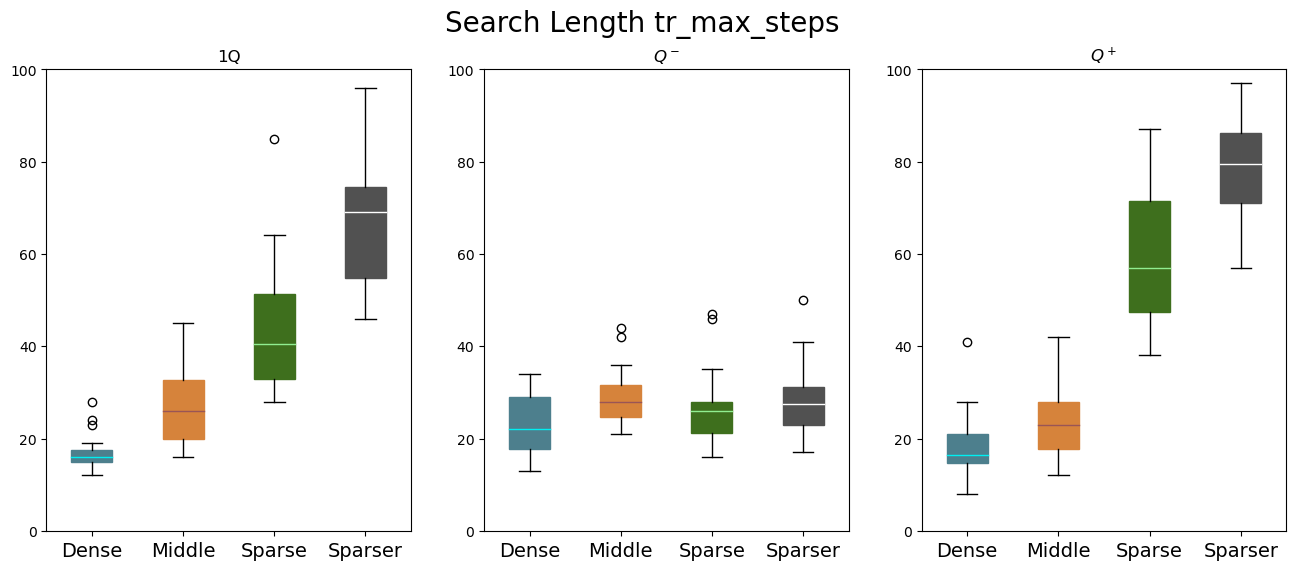

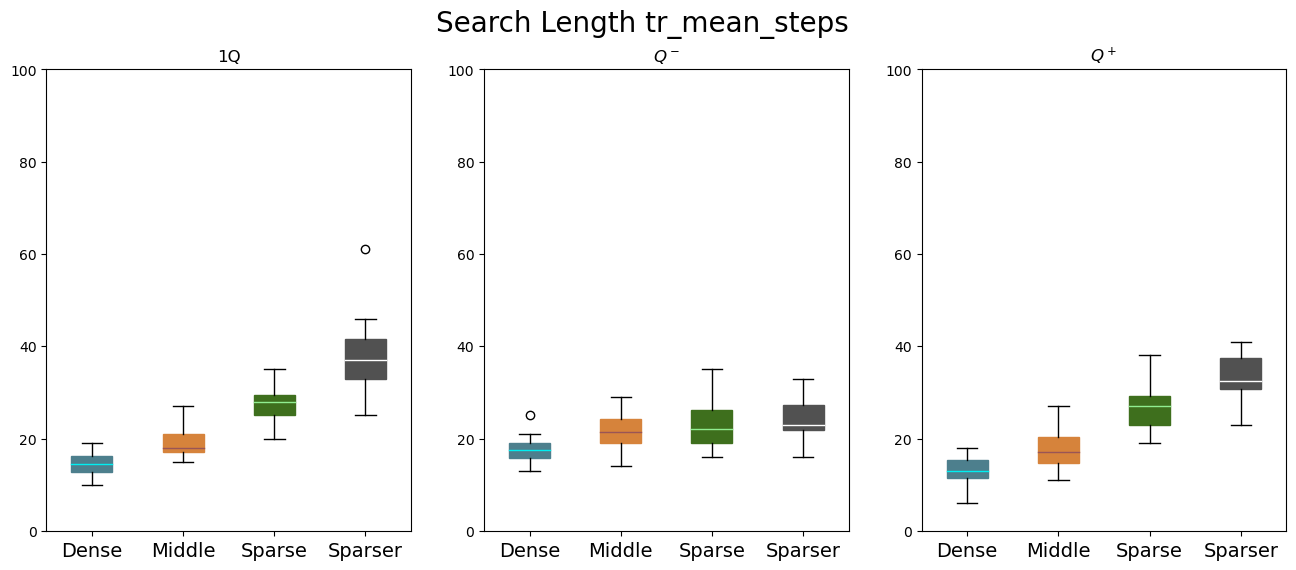

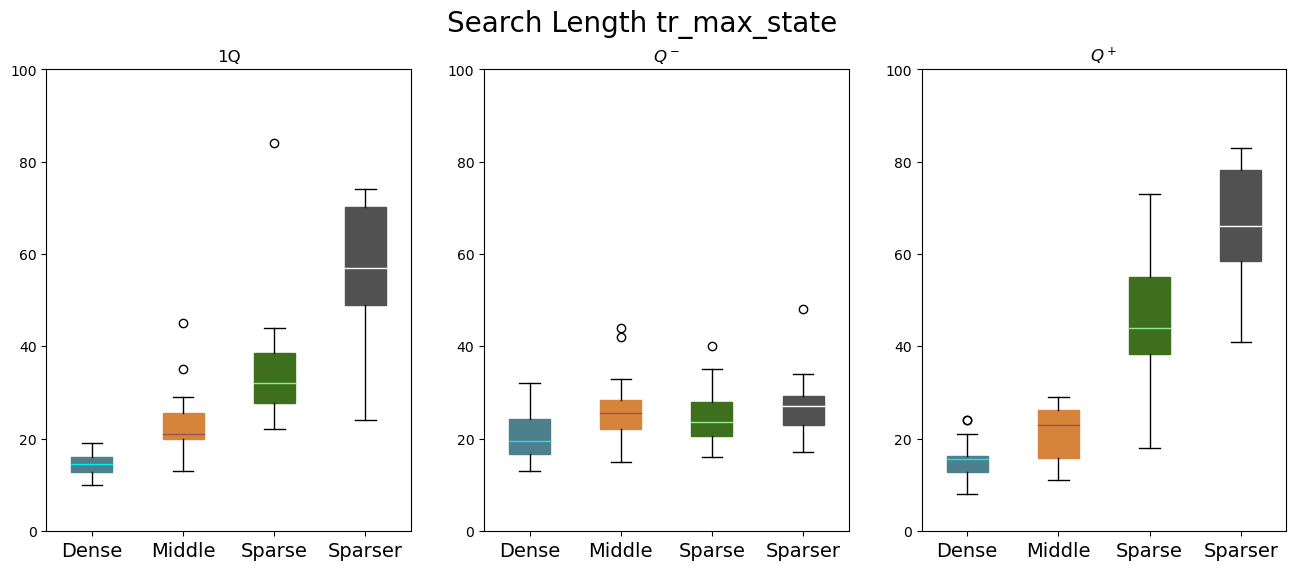

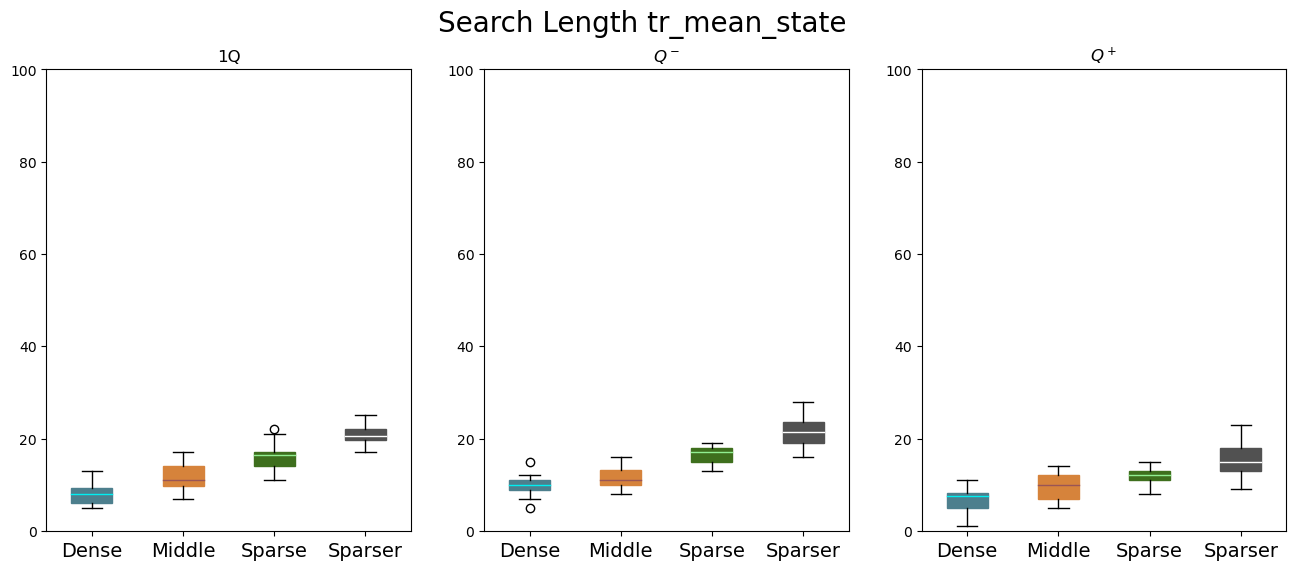

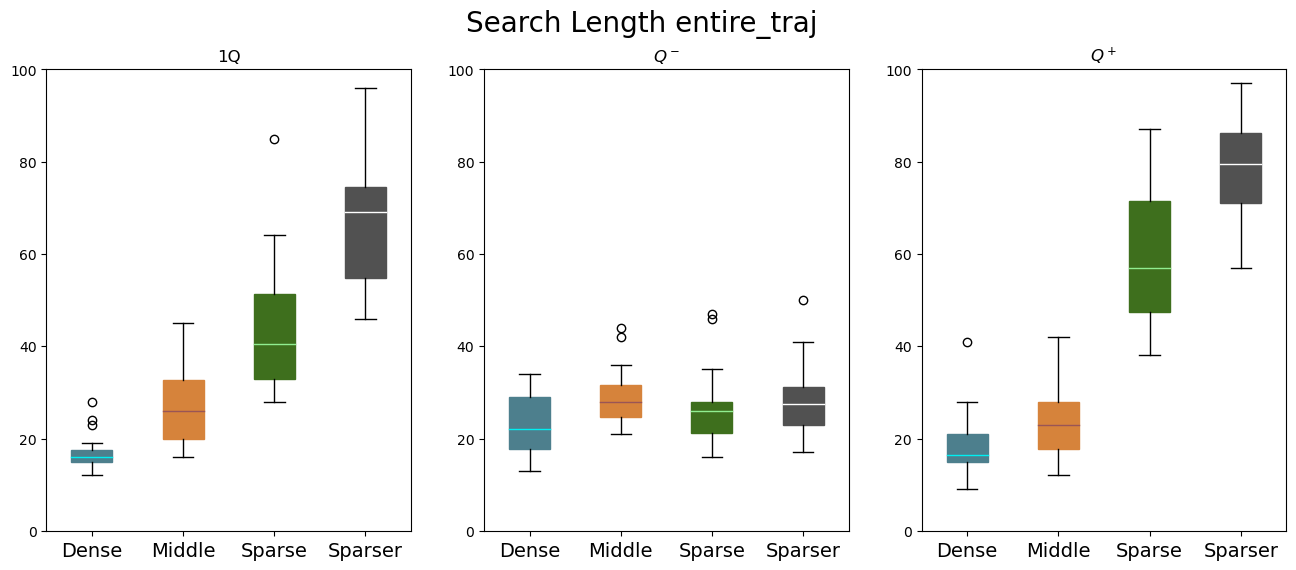

In [30]:
for met_name in metric_names +['entire_traj']:
  search_len_single = [[], [], [], []]
  search_len_qmin = [[], [], [], []]
  search_len_qplus = [[], [], [], []]
  if met_name != 'entire_traj':
    met_single = metrics['single_Q'][met_name]
    met_qmin = metrics['two_Q'][met_name]
    met_qplus = metrics['two_Q'][met_name]
  
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            search_len_single[i].append(compute_search_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 501, count_from=0 ) ) 
            search_len_qmin[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) )
            search_len_qplus[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) )
          else:
            search_len_single[i].append(compute_search_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met_single[i][j]), count_from=0) ) 
            search_len_qmin[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qmin[i][j]), count_from=0 ) )  
            search_len_qplus[i].append(compute_search_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qplus[i][j]) + 502, count_from=502 ) )


  fig, axes = plt.subplots(1, 3, figsize=(16, 6))
  axes = axes.flatten()
  fig.suptitle(f"Search Length {met_name} ", fontsize=20)
  for ax, values, title in zip(axes, [search_len_single, search_len_qmin, search_len_qplus], ['1Q', '$Q^-$', '$Q^+$']):
    ax.set_title(f"{title}")
    b = ax.boxplot(values, patch_artist=True)
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(box_colors[j])
        b['medians'][j].set_color(median_colors[j])
    ax.set_xticklabels(data_labels, fontsize=14)
    ax.set_ylim([-0.1, 100])
  fig.savefig(f"{out_path}/characterization/search_length_{met_name}_2qvs1q_opt_tau.pdf", bbox_inches='tight')
#  plt.close(fig)


### Cast-Width

In [112]:
for met_name in metric_names +['entire_traj']:
  cast_width_single = [[], [], [], []]
  cast_width_qmin = [[], [], [], []]
  cast_width_qplus = [[], [], [], []]
  if met_name != 'entire_traj':
    met_single = metrics['single_Q'][met_name]
    met_qmin = metrics['two_Q'][met_name]
    met_qplus = metrics['two_Q'][met_name]
  
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          if met_name == 'entire_traj':
            cast_width_single[i].append(compute_cast_width(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 501, count_from=0 ) ) 
            cast_width_qmin[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) )
            cast_width_qplus[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) )
          else:
            cast_width_single[i].append(compute_cast_width(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met_single[i][j]), count_from=0) ) 
            cast_width_qmin[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qmin[i][j]), count_from=0 ) )  
            cast_width_qplus[i].append(compute_cast_width(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qplus[i][j]) + 502, count_from=502 ) )


  fig, axes = plt.subplots(1, 3, figsize=(16, 6))
  axes = axes.flatten()
  fig.suptitle(f"Cast Width {met_name}", fontsize=20)
  for ax, values, title in zip(axes, [cast_width_single, cast_width_qmin, cast_width_qplus], ['Single Q', '$Q^-$', '$Q^+$']):
    ax.set_title(f"{title}")
    b = ax.boxplot(values, patch_artist=True)
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(box_colors[j])
        b['medians'][j].set_color(median_colors[j])
    ax.set_xticklabels(data_labels, fontsize=14)

  fig.savefig(f"{out_path}/characterization/cast_width_{met_name}_2qvs1q_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


### Backtracking Length

In [113]:
for met_name in metric_names +['entire_traj']:
  bck_len_single = [[], [], [], []]
  bck_len_qmin = [[], [], [], []]
  bck_len_qplus = [[], [], [], []]
  if met_name != 'entire_traj':
    met_single = metrics['single_Q'][met_name]
    met_qmin = metrics['two_Q'][met_name]
    met_qplus = metrics['two_Q'][met_name]
  
  for (i, setting) in enumerate(settings):
      for (j, seed) in enumerate(agent_seeds):
          # if met_name == 'entire_traj':
          #   bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", 1003, count_from=502 ) ) 
          # else:
          #   bck_len[i].append(compute_backtracking_length(f"{base_dir}/{setting}/agent_{seed}/tau_{tau}/Q_stored/Qfun.npy", round(met[i][j]) + 502, count_from=502) ) 

          if met_name == 'entire_traj':
            bck_len_single[i].append(compute_backtracking_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", 501, count_from=0 ) ) 
            bck_len_qmin[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 502, count_from=0 ) )
            bck_len_qplus[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", 1003, count_from=502 ) )
          else:
            bck_len_single[i].append(compute_backtracking_length(f"{base_dir}/single_Q/{setting}/agent_{seed}/Q_stored/Qfun.npy", round(met_single[i][j]), count_from=0) ) 
            bck_len_qmin[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qmin[i][j]), count_from=0 ) )  
            bck_len_qplus[i].append(compute_backtracking_length(f"{base_dir}/two_Q/{setting}/agent_{seed}/tau_{opt_taus[i]}/Q_stored/Qfun.npy", round(met_qplus[i][j]) + 502, count_from=502 ) )


  fig, axes = plt.subplots(1, 3, figsize=(16, 6))
  axes = axes.flatten()
  fig.suptitle(f"Backtracking Length {met_name}", fontsize=20)
  for ax, values, title in zip(axes, [bck_len_single, bck_len_qmin, bck_len_qplus], ['Single Q', '$Q^-$', '$Q^+$']):
    ax.set_title(f"{title}")
    b = ax.boxplot(values, patch_artist=True)
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(box_colors[j])
        b['medians'][j].set_color(median_colors[j])
    ax.set_xticklabels(data_labels, fontsize=14)

  fig.savefig(f"{out_path}/characterization/backtracking_length_{met_name}_2qvs1q_opt_tau.pdf", bbox_inches='tight')
  plt.close(fig)


## Two-Single Q-Agent

In [114]:
agent = TwoQAgent(horizon=500)
out_path = './plots/two_single_Q'
taus = [3, 5, 10, 25]#, 50, 100, 200, 2000] #[3, 5, 10, 25, 50, 100, 200]

In [115]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_single_Q"

#/storage/rando/pynav_results_new/two_single_Q/agent_1259/tau_5/test/dense/


In [ ]:


for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  for i in range(len(settings)):
      setting = settings[i] 
      c_rewards = []
      speeds = []
      convergence = []

      for seed in agent_seeds:

          with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_{tau}/test/{setting}/test_summary.log", 'r') as f:
              line = f.readline().split(',')
              c_rewards.append(float(line[0]))
              speeds.append(float(line[2]))
              convergence.append(float(line[4]))
      creward_data.append(c_rewards)
      speed_data.append(speeds)
      conv_data.append(convergence)
      

  # num_settings = 4
  # num_subgroups = 4
  # positions = []
  # group_width = 1.0
  # subgroup_spacing = 0.75 

  # for i in range(num_settings):
  #     base = i * group_width * num_subgroups  
  #     positions += [base + j * subgroup_spacing for j in range(num_subgroups)]

  positions = range(len(settings))
  fig, ax = plt.subplots(1, 3, figsize=(22, 6))
  b1 = ax[0].boxplot(creward_data, positions=positions, patch_artist=True)
  b2 = ax[1].boxplot(speed_data, positions=positions, patch_artist=True)
  b3 = ax[2].boxplot(conv_data, positions=positions, patch_artist=True)


  #print(len(b1), b1)

  for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[i % 4])
      b1['medians'][i].set_color(median_colors[i % 4])
      b2['boxes'][i].set_color(box_colors[i % 4])
      b2['medians'][i].set_color(median_colors[i % 4])
      b3['boxes'][i].set_color(box_colors[i % 4])
      b3['medians'][i].set_color(median_colors[i % 4])

#  xticks = [(i * group_width * num_subgroups) + (group_width / 2) for i in range(num_settings)]
  for i in range(len(ax)):
    ax[i].set_xticks(ticks=positions, labels=data_labels, fontsize=14)

  ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
  ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
  ax[2].set_title("Convergence Ratio", fontsize=18)

  ax[0].set_ylim([0.0, 1.01])
  ax[1].set_ylim([0.0, 1.01])
  ax[2].set_ylim([0.0, 1.01])
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"{out_path}/performance/performance_tau_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)


[--] Plotted for tau = 3
./plots/two_single_Q
[--] Plotted for tau = 5
./plots/two_single_Q
[--] Plotted for tau = 10
./plots/two_single_Q
[--] Plotted for tau = 25
./plots/two_single_Q


## Q-usage

In [101]:
agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_single_Q"

for tau in taus:
  creward_data, speed_data, conv_data = [],[],[]
  fig, axes = plt.subplots(2,2, figsize=(12, 6))
  axes = axes.flatten()
  for i in range(len(settings)):
      ax = axes[i]
      setting = settings[i] 
      Q_v = {}
      Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
      for seed in agent_seeds:

          with open(f"{base_dir}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_map.log", 'r') as f:
              for line in f.readlines():
                  splitted = line.split(',')
                  
                  y_pos = int(splitted[0])
                  x_pos = int(splitted[1])
                  if y_pos not in Q_v:
                      Q_v[y_pos] = {}
                  if x_pos not in Q_v[y_pos]:
                      Q_v[y_pos][x_pos] = []
                  Q_v[y_pos][x_pos].append(float(splitted[2]))
      for y_pos, xmap in Q_v.items():
          for x_pos, vals in xmap.items():
              Q_map[y_pos, x_pos] = np.mean(vals)

      new_data = data_environments[noise_thresholds[i]]
      ax.set_title(f"Trained and Test on {setting}")
      im =ax.imshow(Q_map, origin='lower', vmin=0.0, vmax=1.0)
  fig.tight_layout()
  fig.colorbar(im, ax=axes.ravel().tolist(), location='bottom')    
  print(f"[--] Plotted for tau = {tau}")
  fig.savefig(f"./plots/two_single_Q/performance/two_q_usage_{tau}.pdf", bbox_inches='tight')
  plt.close(fig)

/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 3


/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 5


/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 10


/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: divide by zero encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)
/tmp/ipykernel_338316/2206139612.py:13: RuntimeWarning: invalid value encountered in divide
  Q_map = np.zeros((data.shape[1], data.shape[2])) / 0 #np.full((data.shape[1], data.shape[2]), -1.0)


[--] Plotted for tau = 25


In [58]:
Q_usage = []
Q_usage_std = []
taus = [2, 5, 10, 25, 50, 100]

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']
base_dir = "/storage/rando/pynav_results_new/two_single_Q"


Q_settings = []
for setting in settings:
  Qmin_usage, Qplus_usage = [], []
  Q = []
  Q_taus = []
  for tau in taus:
    minus_usage, plus_usage = [], []
    Q_agents = []
    for seed in agent_seeds:
      with open(f"{base_dir}/agent_{seed}/tau_{tau}/test/{setting}/Q_used_list.log", 'r') as f:
        lines = f.readlines()
        for line in lines:
          splitted = line.split(',')
          # if int(splitted[0]) == 0:
          #   continue
          minus_usage.append(float(splitted[1]))
          plus_usage.append(float(splitted[2]))
      Q_m, Q_p = np.sum(minus_usage), np.sum(plus_usage)
      Q_agents.append(Q_m / Q_p)
    # Q_agents contains Q_m / Q_p for each agent at given tau for the given setting
    Q_taus.append(Q_agents)
  Q_settings.append(Q_taus)
  #   minus_usage = np.array(minus_usage)
  #     print(minus_usage, plus_usage)
  #     print("-")
  #   Qmin_usage.append(np.sum(minus_usage))
  #   Qplus_usage.append(np.sum(plus_usage))
    
  # Qmin_usage = np.array(Qmin_usage)
  # Qplus_usage = np.array(Qplus_usage)
  # Q_usage.append(Qmin_usage / Qplus_usage)
        

In [60]:
Q_settings = np.array(Q_settings)

In [61]:
Q_settings

array([[[ 0.60556169,  0.54617927,  0.58517767,  0.60081179,
          0.60028826,  0.6105203 ,  0.64781526,  0.61172243,
          0.59757224,  0.61688192,  0.60758604,  0.60069611,
          0.58131545,  0.57896971,  0.57660226,  0.55990739,
          0.56756621,  0.56567607,  0.56974526,  0.57547036],
        [ 1.24851465,  1.08076779,  1.16249011,  1.16463844,
          1.16959223,  1.16979955,  1.23599116,  1.17213037,
          1.12926197,  1.16185447,  1.13957409,  1.12150455,
          1.08874167,  1.07481349,  1.05981356,  1.02869459,
          1.04350511,  1.03769409,  1.04105956,  1.05292163],
        [ 2.98728817,  2.22681081,  2.32800341,  2.3938111 ,
          2.44183989,  2.43211974,  2.53554452,  2.43999329,
          2.33224015,  2.34148665,  2.28403144,  2.22243567,
          2.18586738,  2.13334376,  2.11629341,  2.05304823,
          2.07873132,  2.07447222,  2.08288707,  2.10356181],
        [ 5.738501  ,  3.5681271 ,  4.2295855 ,  4.98642713,
          5.57371817,

In [66]:
len(Q_settings[i]), len(taus)

(6, 6)

6 6
6 6
6 6
6 6


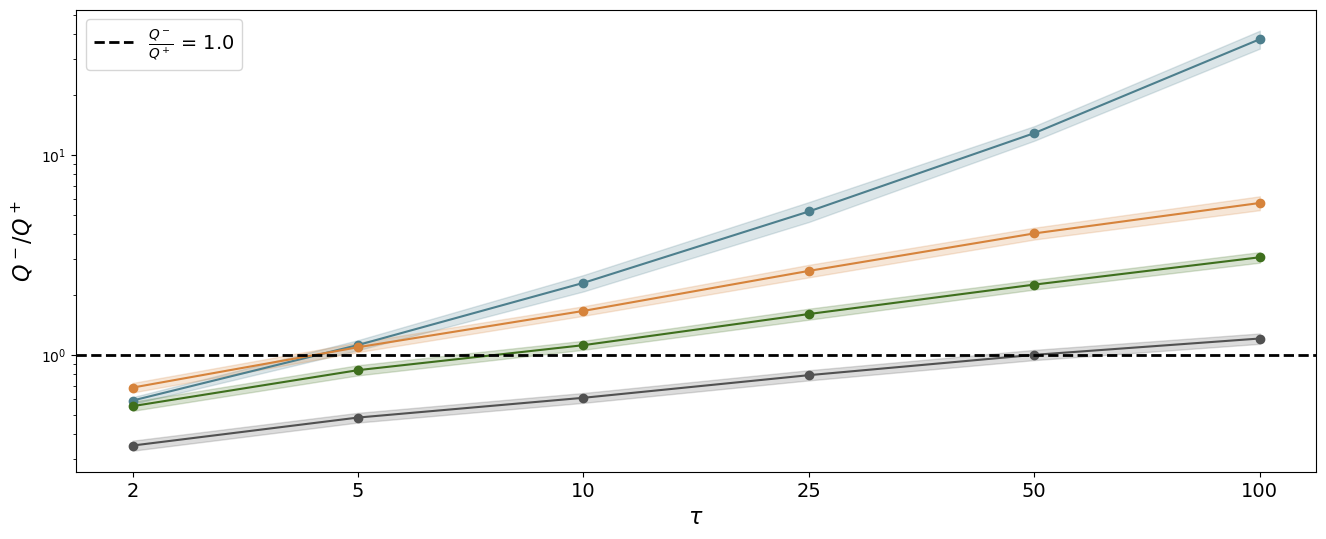

In [75]:


fig, ax = plt.subplots(1, 1, figsize=(16, 6))

for i in range(len(settings)):
  print(len(Q_settings[i]), len(taus))
#  ax.boxplot(Q_settings[i], positions=range(len(taus)), patch_artist=True, showfliers=False, medianprops={'color': median_colors[i]})
  mu, std = np.array([np.mean(Q_settings[i][j]) for j in range(len(taus)) ]), np.array([np.std(Q_settings[i][j]) for j in range(len(taus)) ])
  ax.plot(mu, 'o-', color=box_colors[i], rasterized=True)
  ax.fill_between(range(len(taus)), mu - std, mu + std, color=box_colors[i], alpha=0.2, rasterized=True)
#  ax.plot([np.std(Q_settings[i][j]) for j in range(len(taus)) ], 'o-', color=box_colors[i], rasterized=True)

ax.set_yscale('log')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='$\\frac{Q^-}{Q^+}$ = 1.0', lw=2, rasterized=True)
ax.set_xticks(range(len(taus)), taus, fontsize=14)
ax.set_xlabel("$\\tau$", fontsize=16)
ax.set_ylabel("$Q^-$/$Q^+$", fontsize=16)

ax.legend(fontsize=14)

### Performance

In [ ]:
base_dir = "/storage/rando/pynav_results_new"

for (i, setting) in ['dense', 'middle', 'sparse', 'sparser']:
  fig, axes = plt.subplots(4, 3, figsize=(20, 12))
  for setting_idx, test_setting in enumerate(['dense', 'middle', 'sparse', 'sparser']):
    ax = axes[setting_idx]
    creward_data, speed_data, conv_data = [],[],[]
    c_rewards = []
    speeds = []
    convergence = []

    tick_labels = ['1Q'] + [f'$\\tau = {tau}$' for tau in taus]

    for seed in agent_seeds:
      with open(f"{base_dir}/single_Q/{setting}/agent_{seed}/test/{test_setting}/test_summary.log", 'r') as f:
        splitted = f.readline().split(',')
        c_rewards.append(float(splitted[0]))
        speeds.append(float(splitted[2]))
        convergence.append(float(splitted[4]))

    creward_data.append(c_rewards)
    speed_data.append(speeds)
    conv_data.append(convergence)

    for tau in taus:
      c_rewards = []
      speeds = []
      convergence = []
      for seed in agent_seeds:
        with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_{tau}/test/{test_setting}/test_summary.log", 'r') as f:
          splitted = f.readline().split(',')
          c_rewards.append(float(splitted[0]))
          speeds.append(float(splitted[2]))
          convergence.append(float(splitted[4]))

      creward_data.append(c_rewards)
      speed_data.append(speeds)
      conv_data.append(convergence)


    fig.suptitle(f"Trained on {setting}", fontsize=20)
    b1 = ax[0].boxplot(creward_data,  patch_artist=True)
    b2 = ax[1].boxplot(speed_data,  patch_artist=True)
    b3 = ax[2].boxplot(conv_data,  patch_artist=True)

    for i in range(len(b1['boxes'])):
        b1['boxes'][i].set_color(box_colors[setting_idx])
        b1['medians'][i].set_color(median_colors[setting_idx])
        b2['boxes'][i].set_color(box_colors[setting_idx])
        b2['medians'][i].set_color(median_colors[setting_idx])
        b3['boxes'][i].set_color(box_colors[setting_idx])
        b3['medians'][i].set_color(median_colors[setting_idx])

    for i in range(len(ax)):
        ax[i].set_xticks(ticks=range(1, len(taus) + 2), labels=tick_labels, fontsize=14)
#    ax[0].set_ylim([0.3, 0.8])
    if setting_idx == 0:
      ax[0].set_title("Cumulative Reward ($G$)", fontsize=18)
      ax[1].set_title("Speed ($T_{min}/T$)", fontsize=18)
      ax[2].set_title("Convergence Ratio", fontsize=18)

  fig.tight_layout()
  fig.savefig(f"{out_path}/performance/tau_comparison_{setting}.pdf", bbox_inches='tight')
  plt.close(fig)


In [117]:

agent_seeds = [1259, 1574, 1889, 2204, 2519, 2834, 314, 3149, 3464, 3779, 4094, 4409, 4724, 5039, 5354, 5669, 5984, 629, 6299, 944]
settings = ['dense', 'middle', 'sparse', 'sparser']

opt_tau = [2, 2, 5, 25]
opt_tau_heur = [5, 5, 10, 50]
base_dir = "/storage/rando/pynav_results_new"


for (tr_setting_id, tr_setting) in enumerate(settings):
  creward = {setting : [[] for _ in range(3)] for setting in settings}
  speed = {setting : [[] for _ in range(3)] for setting in settings}
  convergence = {setting : [[] for _ in range(3)] for setting in settings}

  for (te_setting_id, setting) in enumerate(settings):
      for seed in agent_seeds:
            # single Q
            with open(f"{base_dir}/single_Q/{tr_setting}/agent_{seed}/test/{setting}/test_summary.log", 'r') as f:
              splitted = f.readline().split(',')
              creward[setting][0].append(float(splitted[0]))
              speed[setting][0].append(float(splitted[2]))
              convergence[setting][0].append(float(splitted[4]))

            # two Q (trained)
            with open(f"{base_dir}/two_Q/{tr_setting}/agent_{seed}/tau_{opt_tau[tr_setting_id]}/test/{setting}/test_summary.log", 'r') as f:
              splitted = f.readline().split(',')
              creward[setting][1].append(float(splitted[0]))
              speed[setting][1].append(float(splitted[2]))
              convergence[setting][1].append(float(splitted[4]))
              
            # two Q (heuristic)
            with open(f"{base_dir}/two_single_Q/agent_{seed}/tau_{opt_tau_heur[tr_setting_id]}/test/{setting}/test_summary.log", 'r') as f:
              splitted = f.readline().split(',')
              creward[setting][2].append(float(splitted[0]))
              speed[setting][2].append(float(splitted[2]))
              convergence[setting][2].append(float(splitted[4]))

            # for i in [0, 1]:       
            #     with open(f"{base_dir}/{tr_setting}/agent_{seed}/tau_{tau}/test/{setting}/only_Q_{i}/test_summary.log", 'r') as f:
            #       splitted = f.readline().split(',')
            #       creward[setting][i + 1].append(float(splitted[0]))
            #       speed[setting][i + 1].append(float(splitted[2]))
            #       convergence[setting][i + 1].append(float(splitted[4]))



  fig, axes = plt.subplots(3, 4, figsize=(20, 10))

  for (idx, label) in zip(range(4), data_labels):
    b1 = axes[0, idx].boxplot(creward[data_labels[idx].lower()], positions=range(3), patch_artist=True)
    b2 = axes[1, idx].boxplot(speed[data_labels[idx].lower()], positions=range(3), patch_artist=True)
    b3 = axes[2, idx].boxplot(convergence[data_labels[idx].lower()], positions=range(3), patch_artist=True)

    for i in range(len(b1['boxes'])):
      b1['boxes'][i].set_color(box_colors[idx])
      b1['medians'][i].set_color(median_colors[idx])
      b2['boxes'][i].set_color(box_colors[idx])
      b2['medians'][i].set_color(median_colors[idx])
      b3['boxes'][i].set_color(box_colors[idx])
      b3['medians'][i].set_color(median_colors[idx])

    axes[0, idx].set_xticks(range(3), ['single Q', 'two Q (tr)', 'two Q (heur)'], fontsize=14)
    axes[1, idx].set_xticks(range(3), ['single Q', 'two Q (tr)', 'two Q (heur)'], fontsize=14)
    axes[2, idx].set_xticks(range(3), ['single Q', 'two Q (tr)', 'two Q (heur)'], fontsize=14)
  axes[0, 0].set_ylabel("Cumulative Reward", fontsize=16)
  axes[1, 0].set_ylabel("Speed ($T_{min} / T$)", fontsize=16)
  axes[2, 0].set_ylabel("Convergence", fontsize=16)
  fig.suptitle(f"Trained on {tr_setting}",fontsize=22)
  fig.tight_layout()
  fig.savefig(f"./plots/two_Q/single_vs_two/performance_comparison_vs_single_opt_tau_{tr_setting}.pdf", bbox_inches='tight')
  plt.close(fig)
